In [23]:
from audioop import error
from distutils.core import setup_keywords
from functools import total_ordering
from idlelib import history
from pickletools import optimize

import matplotlib
import numpy as np
from IPython.core.pylabtools import figsize
from PIL.ImageOps import scale
from jupyter_builder.jupyterlab_semver import test_set
from matplotlib import axes
from matplotlib.lines import lineStyles
from narwhals import col
from networkx.algorithms.bipartite.basic import color
from numpy.ma.core import size
from pandas.compat.numpy.function import validate_sum
from sympy.abc import alpha
from sympy.core.random import sample
from sympy.printing.pretty.pretty_symbology import line_width
from torch import return_types
from torch.cuda.nvtx import mark
from torch.distributed import device_mesh
from torch.nn import Sigmoid
from torch.nn.modules import loss
from torch.utils.flop_counter import suffixes
from torchgen.api.ufunc import dispatchstub_type
from torchgen.native_function_generation import self_to_out_signature

A = np.array([[1,2],
              [3,4]])
B = np.array([[5,6],
              [7,8]])
print("A @ B = \n",A@B)#@是矩阵乘法
print("A * B = \n",A*B)#*是元素乘法

A @ B = 
 [[19 22]
 [43 50]]
A * B = 
 [[ 5 12]
 [21 32]]


In [24]:
X = np.random.randn(100,3)
W = np.random.randn(3,1)
y = X @ W
print("X:",X.shape,"W:",W.shape,"y:",y.shape)
try:
    bad = X @ X
except ValueError as e:
    print("报错了，这是故意的:",e) #tru——except的意识是如果这里错了，我就怎么样

X: (100, 3) W: (3, 1) y: (100, 1)
报错了，这是故意的: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 100 is different from 3)


In [25]:
X = np.random.randn(3,5)
print(X.shape)
print(X.T.shape) #.T是转置矩阵


(3, 5)
(5, 3)


A = np.array([[2,0,1],[1,3,2]])
print(A.shape)

In [26]:
v = np.array([3.0,4.0])
print(np.linalg.norm(v)) #np.linalg.norm是范数

5.0


In [27]:
A = np.array([[2,0,1],
              [1,3,2]])
print(A.shape)

(2, 3)


In [30]:
A = np.array([[2,0],
              [1,3]])
B = np.array([[1,4],
              [2,5]])
print("A @ B =")
print(A @ B)
print()
print("B @ A=")
print(B @ A)

A @ B =
[[ 2  8]
 [ 7 19]]

B @ A=
[[ 6 12]
 [ 9 15]]


In [35]:
X = np.random.randn(64,784)
W = np.random.randn(784,10)
b = np.random.randn(10)

y = X @ W + b
print(y.shape)


(64, 10)


In [3]:
import numpy as np
def f(x):
    return x**2+3*x+1
def numerical_grad(f,x,h=1e-5):
    return(f(x+h)-f(x-h))/(2*h)#两点之间计算斜率
def analytic_grad(x):
    return 2*x+3
for x in [-2.0,0.0,1.5,3.0]:
    num = numerical_grad(f,x)
    ana = analytic_grad(x)
    print(f"x={x:5.1f} 数值={num:9.5f} 手算={ana:9.5f} 差={abs(num-ana):e}")

x= -2.0 数值= -1.00000 手算= -1.00000 差=3.785783e-11
x=  0.0 数值=  3.00000 手算=  3.00000 差=2.551293e-12
x=  1.5 数值=  6.00000 手算=  6.00000 差=1.281242e-10
x=  3.0 数值=  9.00000 手算=  9.00000 差=1.921876e-10


In [13]:
import numpy as np
def f(x):
    return (x-3)**2+2
def grad(x):
    return 2*(x-3)
x= -10.0 #随便找个起点
lr=0.1

for i in range(50):
    g=grad(x)
    x=x-lr*g

    if i % 5 == 0:
        print(f"第{i:2d}步 x={x:8.4f} f(x)={f(x):8.4f}")
print(f"\n最终 x = {x:.6f}，应该是 3")

第 0步 x= -7.4000 f(x)=110.1600
第 5步 x= -0.4079 f(x)= 13.6136
第10步 x=  1.8833 f(x)=  3.2470
第15步 x=  2.6341 f(x)=  2.1339
第20步 x=  2.8801 f(x)=  2.0144
第25步 x=  2.9607 f(x)=  2.0015
第30步 x=  2.9871 f(x)=  2.0002
第35步 x=  2.9958 f(x)=  2.0000
第40步 x=  2.9986 f(x)=  2.0000
第45步 x=  2.9995 f(x)=  2.0000

最终 x = 2.999814，应该是 3


In [4]:
import numpy as np
def f(x):
    return 5*x**3-2*x+7
def numerical_grad(f,x,h=1e-5):
    return (f(x+h)-f(x-h))/(2*h)#数值方法求导，一条割线的两个端点的斜率无限接近切线
def analytic_grad(x):
    return 15*x**2-2#手算导数
x = 2.0
num = numerical_grad(f,x)
ana = analytic_grad(x)
print(f"手算={ana:.6f} 数值={num:.6f} 差={abs(ana-num):.2e}")


手算=58.000000 数值=58.000000 差=1.36e-09


In [13]:
import numpy as np
def f(x):
    return (x+4)**2
def grad(x):
    return 2*(x+4)
x = 6.0
lr = 0.1
for i in range(30):
    g = grad(x)
    x = x-lr*g
    print(f"第{i:2d}步 x={x:8.4f} f(x)={f(x):10.4f}")
print(f"\n最终 x = {x:.6f},应该是-4")

第 0步 x=  4.0000 f(x)=   64.0000
第 1步 x=  2.4000 f(x)=   40.9600
第 2步 x=  1.1200 f(x)=   26.2144
第 3步 x=  0.0960 f(x)=   16.7772
第 4步 x= -0.7232 f(x)=   10.7374
第 5步 x= -1.3786 f(x)=    6.8719
第 6步 x= -1.9028 f(x)=    4.3980
第 7步 x= -2.3223 f(x)=    2.8147
第 8步 x= -2.6578 f(x)=    1.8014
第 9步 x= -2.9263 f(x)=    1.1529
第10步 x= -3.1410 f(x)=    0.7379
第11步 x= -3.3128 f(x)=    0.4722
第12步 x= -3.4502 f(x)=    0.3022
第13步 x= -3.5602 f(x)=    0.1934
第14步 x= -3.6482 f(x)=    0.1238
第15步 x= -3.7185 f(x)=    0.0792
第16步 x= -3.7748 f(x)=    0.0507
第17步 x= -3.8199 f(x)=    0.0325
第18步 x= -3.8559 f(x)=    0.0208
第19步 x= -3.8847 f(x)=    0.0133
第20步 x= -3.9078 f(x)=    0.0085
第21步 x= -3.9262 f(x)=    0.0054
第22步 x= -3.9410 f(x)=    0.0035
第23步 x= -3.9528 f(x)=    0.0022
第24步 x= -3.9622 f(x)=    0.0014
第25步 x= -3.9698 f(x)=    0.0009
第26步 x= -3.9758 f(x)=    0.0006
第27步 x= -3.9807 f(x)=    0.0004
第28步 x= -3.9845 f(x)=    0.0002
第29步 x= -3.9876 f(x)=    0.0002

最终 x = -3.987621,应该是-4


第 0步 x=  4.0000 f(x)=   64.0000
第 5步 x= -1.3786 f(x)=    6.8719
第10步 x= -3.1410 f(x)=    0.7379
第15步 x= -3.7185 f(x)=    0.0792
第20步 x= -3.9078 f(x)=    0.0085
第25步 x= -3.9698 f(x)=    0.0009


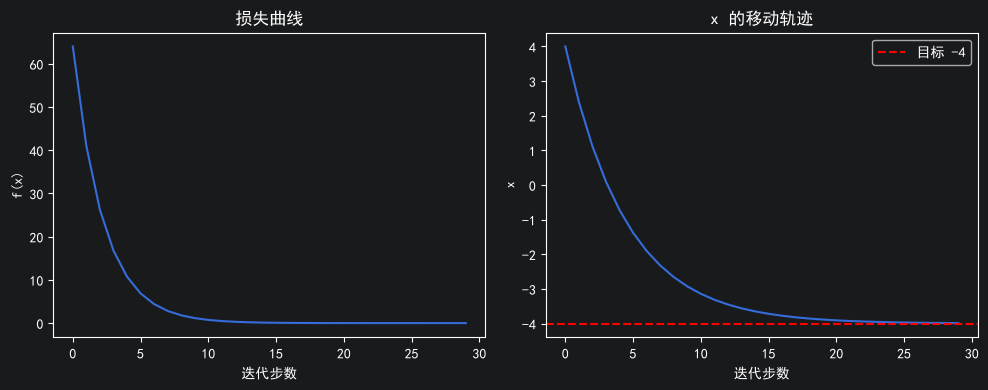


最终 x = -3.987621，应该是 -4


In [22]:
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

def f(x):
    return (x+4)**2

def grad(x):
    return 2*(x+4)

x = 6.0
lr = 0.1 #0 < lr < 1，lr ≥ 1 就发散
losses = []
xs = []

for i in range(30):
    g = grad(x)
    x = x - lr*g
    losses.append(f(x))
    xs.append(x)
    if i % 5 == 0:
        print(f"第{i:2d}步 x={x:8.4f} f(x)={f(x):10.4f}")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)#前面1，2指的是造一个1*2的货架，第三个1指的是拿第一个货物
plt.plot(losses)
plt.title("损失曲线")
plt.xlabel("迭代步数")
plt.ylabel("f(x)")

plt.subplot(1, 2, 2)#前面1，2指的是造一个1*2的货架，第三个2指的是拿第一个货物
plt.plot(xs)
plt.axhline(-4, color='red', linestyle='--', label='目标 -4')
plt.title("x 的移动轨迹")
plt.xlabel("迭代步数")
plt.ylabel("x")
plt.legend()

plt.tight_layout()
plt.show()

print(f"\n最终 x = {x:.6f}，应该是 -4")

In [7]:
import  numpy as np#伯努利分布
#患病概率 p=0.02 的人群，抽10000人
p = 0.02
samples = np.random.random(10000)<p#给10000个人各自掷一次“2%中奖”的骰子，然后数数中了几个
print("患病人数:",samples.sum(),"比例:",samples.mean())

患病人数: 227 比例: 0.0227


In [9]:
import  numpy as np#正态分布
samples = np.random.normal(loc=170,scale=8,size=10000)#身高
print("均值:",samples.mean(),"标准差:",samples.std())#samples.mean()这个mean就是总数/总人数

均值: 169.92316120971026 标准差: 8.055788953186877


In [14]:
data = np.random.normal(170,8,100000)
print("期望：",data.mean())#mean()=总数/个数
print("方差：",data.var())#var()=方差--衡量数据散的有多开，是每个数离均值多远的平方1的平均值
print("标准差：",data.std())#标准差就是方差的平方根
#均值 ± 1 个标准差   →   覆盖约 68% 的人
# 均值 ± 2 个标准差   →   覆盖约 95% 的人
# 均值 ± 3 个标准差   →   覆盖约 99.7% 的人

期望： 170.01777580930147
方差： 63.71561493972561
标准差： 7.9822061449029


In [21]:
import numpy as np
np.random.seed(42) #固定是随机种子，结果可复现
N = 1_000_000 #一百万人
prevalence = 0.01#患病率1%
sensitivity = 0.99#灵敏度：患病者测出阳性的概率
specificity = 0.95#特异度: 健康者测出阴性的概率
#1.生成真实状态：True=患病
is_sick = np.random.random(N) <  prevalence#数据向量化
#2.根据真实状态决定检测结果
random_vals = np.random.random(N)
test_positive = np.where(
    is_sick,
    random_vals < sensitivity, #患病者：以99%概率阳性
    random_vals > specificity  #健康者：以5%概率阳性
)
# 3. 统计
n_sick = is_sick.sum()
n_positive = test_positive.sum()
n_true_positive = (is_sick & test_positive).sum()

print(f"总人数: {N:,}")
print(f"真实患病: {n_sick:,}")
print(f"检测阳性: {n_positive:,}")
print(f"其中真患病: {n_true_positive:,}")
print(f"阳性预测值 PPV = {n_true_positive / n_positive:.4f}")
print(f"理论值 0.1667")

总人数: 1,000,000
真实患病: 9,979
检测阳性: 59,512
其中真患病: 9,879
阳性预测值 PPV = 0.1660
理论值 0.1667


In [37]:
#贝叶斯
import numpy as np
np.random.seed(42)
N = 1000000#1000000人群
prevalence = 0.02#患病率2%
sensitivity = 0.90#灵敏度90%
specificity = 0.98#特异度98%
is_sick = np.random.random(N) <  prevalence#人群中只有2%的人患病,并把这些数据向量化
#2根据真实状态，反映检测结果
random_vals = np.random.random(N)
test_positive = np.where(
    is_sick,
    random_vals < sensitivity,#random_vals是阳性的意思，患病者中阳性的灵敏度为0.90
    random_vals > specificity #random_vals是阳性的意思，健康人群中的特异度是0.98
)
#3统计
n_sick = is_sick.sum()#患病总人数
n_positive = test_positive.sum()#检测阳性总人数
n_true_positive = (is_sick & test_positive).sum()#检测出真患病总人数

print(f"总人数: {N:,}")
print(f"真实患病: {n_sick:,}")
print(f"检测阳性: {n_positive:,}")
print(f"其中真患病: {n_true_positive:,}")
print(f"阳性预测值 PPV = {n_true_positive / n_positive:.4f}")
print(f"理论值 0.47")

总人数: 1,000,000
真实患病: 19,991
检测阳性: 37,565
其中真患病: 18,005
阳性预测值 PPV = 0.4793
理论值 0.47


In [1]:
import numpy as np
np.random.seed(42)
N = 1_000_000
prevalence = 0.02
sensitivity = 0.90
specificity = 0.98

# 1. 生成真实状态：谁真的患病
is_sick = np.random.random(N) < prevalence

# 2. 根据真实状态生成检测结果
random_vals = np.random.random(N)
test_positive = np.where(
    is_sick,
    random_vals < sensitivity,   # 患病的人：90% 被检出
    random_vals > specificity    # 健康的人：2% 被误报
)
# 3. 统计
n_sick = is_sick.sum()
n_positive = test_positive.sum()
n_true_positive = (is_sick & test_positive).sum()
n_negative = (~test_positive).sum()
n_true_negative = ((~is_sick) & (~test_positive)).sum()
print(f"总人数:     {N:,}")
print(f"真实患病:   {n_sick:,}")
print(f"检测阳性:   {n_positive:,}")
print(f"其中真患病: {n_true_positive:,}")
print(f"阳性预测值 PPV = {n_true_positive / n_positive:.4f}")  # 阳性预测值
print(f"\n检测阴性:   {n_negative:,}")
print(f"其中真健康: {n_true_negative:,}")
print(f"阴性预测值 NPV = {n_true_negative / n_negative:.4f}")  # 阴性预测值
# 阴性预测值（NPV）= 真阴性 / 检测阴性


总人数:     1,000,000
真实患病:   19,991
检测阳性:   37,565
其中真患病: 18,005
阳性预测值 PPV = 0.4793

检测阴性:   962,435
其中真健康: 960,449
阴性预测值 NPV = 0.9979


均值:   59.998
标准差: 5.001
μ±2σ 之外的比例: 0.0450


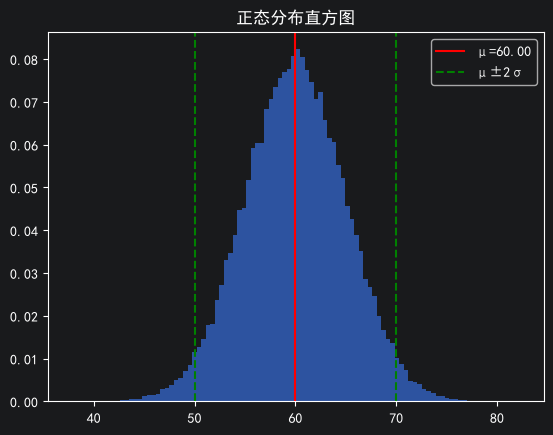

In [11]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
np.random.seed(42)
data = np.random.normal(loc=60, scale=5, size=50000)
print(f"均值:   {data.mean():.3f}")
print(f"标准差: {data.std():.3f}")
mu,sigma = data.mean(),data.std()#均值和标准差
out = np.mean((data < mu - 2*sigma) | (data > mu + 2*sigma))#μ±2σ
print(f"μ±2σ 之外的比例: {out:.4f}")
plt.hist(data,bins=100,density=True,alpha=0.7)
#density是改变纵轴的意思，默认为false，表示箱子里的个数，如果改为true，表示概率密度，bins=100，代表的是切成100个箱子，箱子越多，柱子越细，形状越光滑
plt.axvline(mu, color='r', label=f'μ={mu:.2f}')
plt.axvline(mu - 2*sigma, color='g', linestyle='--', label='μ±2σ')
plt.axvline(mu + 2*sigma, color='g', linestyle='--')
plt.title('正态分布直方图');
plt.legend();
plt.show()

In [5]:
for (i, o) in [(128,64), (64,10)]:
    print(f"{i} -> {o}: {i*o + o}")

128 -> 64: 8256
64 -> 10: 650


In [7]:
import numpy as np
from sklearn.model_selection import train_test_split
N = 1000
X= np.random.randn(N,5)#randn = standard normal（标准正态），均值为 0、标准差为 1 的随机数
y = np.random.randint(0,2,N)#randint(0, 2, 1000) = 生成 [0,2) 之间的随机整数
X_temp,X_test,y_temp,y_test = train_test_split(X,y,test_size=0.15,random_state=42)
X_train,X_val,y_train,y_val = train_test_split(X_temp,y_temp,test_size=0.176,random_state=42)
print(f"训练 {len(X_train)}  验证 {len(X_val)}  测试 {len(X_test)}")

训练 700  验证 150  测试 150


In [10]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
np.random.seed(42)
# ========== 1. 造数据：真实关系是 y = 2.5x + 1，加点噪声 ==========
N = 200
x = np.random.rand(N)*10#随机生成200个0~10之间的数
true_w,true_b = 2.5,1.0
y = true_w * x + true_b + np.random.randn(N) * 1.5#加噪声
# ========== 2. 初始化参数（随便给个数）==========
w = 0.0
b = 0.0
lr = 0.01
losses = []
# ========== 3. 训练循环 ==========
for epoch in range(1000):
    # --- 前向：算预测 ---
    y_pred = w*x+b
    # --- 算损失 ---
    error = y_pred - y
    loss = np.mean(error ** 2)#np.mean(...)求平均 = 总数/个数，用数学写出来就是： loss = (1/N) × Σ eᵢ²
    # --- 反向：算梯度(上面推的公式) ---
    dw = (2 / N) * np.sum(error * x)#损失函数的由来
    db = (2 / N) * np.sum(error)#损失函数的由来
    # --- 更新参数 ---
    w = w - lr*dw
    b = b - lr*db
    if epoch % 100 ==0:
        print(f"epoch{epoch:4d} loss={loss:9.4f} w={w:7.4f} b={b:7.4f}")
print(f"\n学到的: w={w:.4f} b={b:.4f}")
print(f"真实的: w={true_w:.4f} b={true_b:.4f}")

epoch   0 loss= 229.9482 w= 1.7085 b= 0.2640
epoch 100 loss=   2.1555 w= 2.5562 b= 0.7113
epoch 200 loss=   2.1200 w= 2.5283 b= 0.8947
epoch 300 loss=   2.1077 w= 2.5119 b= 1.0027
epoch 400 loss=   2.1034 w= 2.5022 b= 1.0664
epoch 500 loss=   2.1019 w= 2.4965 b= 1.1039
epoch 600 loss=   2.1014 w= 2.4931 b= 1.1261
epoch 700 loss=   2.1012 w= 2.4911 b= 1.1391
epoch 800 loss=   2.1011 w= 2.4900 b= 1.1468
epoch 900 loss=   2.1011 w= 2.4893 b= 1.1513

学到的: w=2.4889 b=1.1540
真实的: w=2.5000 b=1.0000


epoch    0  loss= 229.9482  w= 1.7085  b= 0.2640
epoch  100  loss=   2.1555  w= 2.5562  b= 0.7113
epoch  200  loss=   2.1200  w= 2.5283  b= 0.8947
epoch  300  loss=   2.1077  w= 2.5119  b= 1.0027
epoch  400  loss=   2.1034  w= 2.5022  b= 1.0664
epoch  500  loss=   2.1019  w= 2.4965  b= 1.1039
epoch  600  loss=   2.1014  w= 2.4931  b= 1.1261
epoch  700  loss=   2.1012  w= 2.4911  b= 1.1391
epoch  800  loss=   2.1011  w= 2.4900  b= 1.1468
epoch  900  loss=   2.1011  w= 2.4893  b= 1.1513

学到的: w=2.4889  b=1.1540
真实的: w=2.5000  b=1.0000


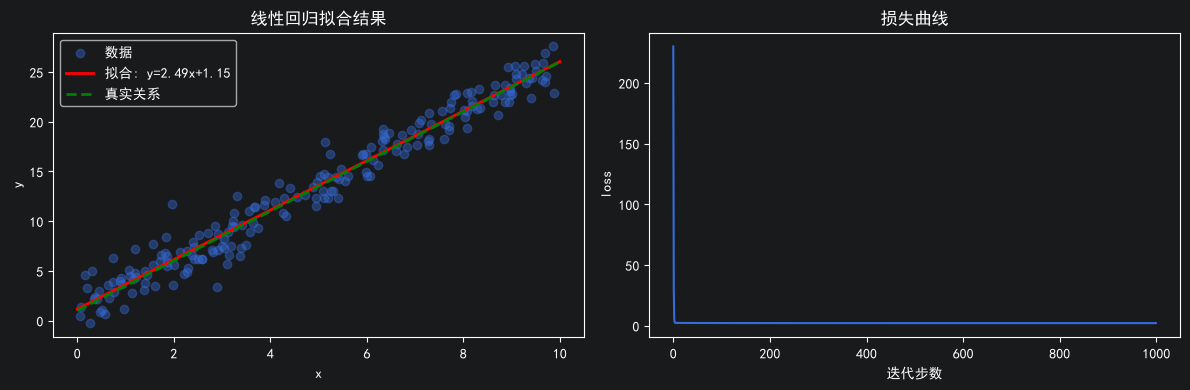

In [29]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
np.random.seed(42)
# ========== 1. 造数据 ==========
N = 200
x = np.random.rand(N) * 10
true_w, true_b = 2.5, 1.0
y = true_w * x + true_b + np.random.randn(N) * 1.5
# ========== 2. 初始化 ==========
w = 0.0
b = 0.0
lr = 0.01
losses = []
# ========== 3. 训练循环 ==========
for epoch in range(1000):
    # --- 前向 ---
    y_pred = w * x + b

    # --- 损失 ---
    error = y_pred - y
    loss = np.mean(error ** 2)
    losses.append(loss)                    # ← 补上

    # --- 梯度 ---
    dw = (2 / N) * np.sum(error * x)
    db = (2 / N) * np.sum(error)

    # --- 更新 ---
    w = w - lr * dw
    b = b - lr * db

    if epoch % 100 == 0:
         print(f"epoch {epoch:4d}  loss={loss:9.4f}  w={w:7.4f}  b={b:7.4f}")
print(f"\n学到的: w={w:.4f}  b={b:.4f}")
print(f"真实的: w={true_w:.4f}  b={true_b:.4f}")
# ========== 4. 画图 ==========
fig, axes = plt.subplots(1, 2, figsize=(12, 4))#fig = 整张画布,axes = 一个装着两个子图的数组
# --- 左图：拟合效果 ---
axes[0].scatter(x, y, alpha=0.4, label='数据')#scatter = 散点图，把200个（x,y）一个个画成点
x_line = np.linspace(0, 10, 100)           # ← 有序的 x，画直线用
axes[0].plot(x_line, w * x_line + b, 'r-', linewidth=2,
            label=f'拟合: y={w:.2f}x+{b:.2f}')
axes[0].plot(x_line, true_w * x_line + true_b, 'g--', linewidth=2,
            label='真实关系')
axes[0].legend()
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_title('线性回归拟合结果')
# --- 右图：损失曲线 ---
axes[1].plot(losses)
axes[1].set_xlabel('迭代步数')
axes[1].set_ylabel('loss')
axes[1].set_title('损失曲线')
plt.tight_layout()
plt.show()

In [38]:
import numpy as np
np.random.seed(42)
N = 200
x = np.random.rand(N)*10
true_w,true_b = 2.5,1.0
y = true_w*x + true_b + np.random.randn(N)*1.5
#拼矩阵
X = np.column_stack([x,np.ones(N)])#(200,2):第一列x，第二列全1
w_vec = np.zeros(2)#初始值[w,b]=[0,0]
lr = 0.01
losses = []
for epoch in range(1000):
    y_pred = X @ w_vec
    error = y_pred - y
    loss = np.mean(error**2)
    grad = (2 / N) * (X.T @ error)#(2,200) @ (200,) - (2,)
    w_vec = w_vec -lr *grad
print("学到的w,b = ",w_vec)
print("真实的w,b = ",[true_w,true_b])

学到的w,b =  [2.48887497 1.15395218]
真实的w,b =  [2.5, 1.0]


In [44]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
np.random.seed(42)
#造数据
N = 200
x = np.random.rand(N)*10
true_w,true_b = -1.8,5.0
y = true_w * x + true_b+np.random.randn(N)*1.5 #加噪声
#初始化参数
w = 0.0
b = 0.0
lr = 0.01
losses = []
#训练循环
for epoch in range(1000):
    #算预测
    y_pred = w*x + b
    #算损失
    error = y_pred - y
    loss = np.mean(error ** 2)
    #反向:算梯度
    dw = (2/N)*np.sum(error * x)
    db = (2/N)*np.sum(error)
    #更新参数
    w = w - lr * dw
    b = b - lr * db
    if epoch % 100 == 0:
        print(f"epoch {epoch:4d}  loss={loss:9.4f}  w={w:7.4f}  b={b:7.4f}")
print(f"\n学到的:  w={w:.4f}  b={b:.4f}")
print(f"真实的:  w={true_w:.4f}  b={true_b:.4f}")

epoch    0  loss=  43.5408  w=-0.6631  b=-0.0722
epoch  100  loss=   4.7436  w=-1.3381  b= 2.0446
epoch  200  loss=   3.0189  w=-1.5326  b= 3.3231
epoch  300  loss=   2.4199  w=-1.6472  b= 4.0765
epoch  400  loss=   2.2118  w=-1.7148  b= 4.5206
epoch  500  loss=   2.1396  w=-1.7546  b= 4.7822
epoch  600  loss=   2.1145  w=-1.7780  b= 4.9365
epoch  700  loss=   2.1057  w=-1.7919  b= 5.0274
epoch  800  loss=   2.1027  w=-1.8000  b= 5.0809
epoch  900  loss=   2.1017  w=-1.8048  b= 5.1125

学到的:  w=-1.8076  b=5.1310
真实的:  w=-1.8000  b=5.0000


In [52]:
import numpy as np
np.random.seed(42)
N = 200
x1 = np.random.rand(N)*10
x2 = np.random.rand(N)*10
x3 = np.random.rand(N)*10
true_a = 2
true_b = -3
true_c = 0.5
true_d = 4
y = true_a*x1 + true_b*x2 + true_c*x3 + true_d
X = np.column_stack([x1,x2,x3,np.ones(N)])#(200,4):第一、二、三列x，第四列全1
w_vec = np.zeros(4)#初始值[a,b,c,d]=[0,0,0,0]
lr = 0.01
losses = []
for epoch in range(1000):
    y_pred = X @ w_vec
    error = y_pred - y
    loss = np.mean(error**2)
    grad =  (2 / N)*(X.T @ error)
    w_vec = w_vec - lr * grad
    if epoch % 200 ==0:
        print(f"epoch {epoch: 4d} loss={loss:10.6f}")
print("\n学到的[a,b,c,d]=",np.round(w_vec,4))
print("真实的[a,b,c,d]=",true_a,true_b,true_c,true_d)

epoch    0 loss=120.434560
epoch  200 loss=  0.711519
epoch  400 loss=  0.344010
epoch  600 loss=  0.166325
epoch  800 loss=  0.080416

学到的[a,b,c,d]= [ 2.0364 -2.9585  0.5396  3.349 ]
真实的[a,b,c,d]= 2 -3 0.5 4


In [5]:
import numpy as np
def sigmoid(z):
    return 1/(1 + np.exp(-z))#np.exp意思是e的-z次方
for z in [-5,-2,0,2,5,10,100]:
    print(f"z={z:3d} sigmoid={sigmoid(z):.4f}")

z= -5 sigmoid=0.0067
z= -2 sigmoid=0.1192
z=  0 sigmoid=0.5000
z=  2 sigmoid=0.8808
z=  5 sigmoid=0.9933
z= 10 sigmoid=1.0000
z=100 sigmoid=1.0000


In [6]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,roc_auc_score)
np.random.seed(42)
#造一个不平衡的二分类数据（模拟医疗场景）
#weights=[0.9,0.1]表示90%负类、10%正类
X,y = make_classification(n_samples=2000,n_features=10,n_informative=5,weights=[0.9,0.1],random_state=42)#n_samples=2000,2000个病人，n_features=10每人10项指标,n_informative=5，其中只有5项真的携带患病信息，另外五项是纯噪声,w[0.9,0.1],90%标0，10%标1，
print("正类比例:",y.mean())
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)#stratify = y：分层抽样，保证且完后的数据和测试集里的数据比例一致
#训练
clf = LogisticRegression(max_iter=1000)
#造机器，从sklearn里拿“逻辑回归”这台机器的图纸
#max_iter=1000，机器的设置，内部最多迭代1000轮
clf.fit(X_train,y_train)
#fit = 拟合，把训练数据喂进去，1600人的特征和答案，黑盒里跑之前写过的五步循环，第一步：猜，第二步：打分，第三步：问方向，第四步：挪一步，第五步：循环
#预测
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:,1]#取正类的概率
print("\n==== 评估结果 ====")
print(f"准确率 Accuracy:{accuracy_score(y_test,y_pred):.4f}")
print(f"精确率 Precision:{precision_score(y_test,y_pred):.4f}")
print(f"召回率 Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1              : {f1_score(y_test, y_pred):.4f}")
print(f"AUC             : {roc_auc_score(y_test, y_prob):.4f}")

print("\n混淆矩阵")
cm = confusion_matrix(y_test,y_pred)
print(cm)
print(f" TN={cm[0,0]} FP={cm[0,1]}")
print(f" FN={cm[1,0]} TP={cm[1,1]}")

正类比例: 0.1035

==== 评估结果 ====
准确率 Accuracy:0.8900
精确率 Precision:0.2000
召回率 Recall   : 0.0244
F1              : 0.0435
AUC             : 0.7644

混淆矩阵
[[355   4]
 [ 40   1]]
 TN=355 FP=4
 FN=40 TP=1


In [7]:
import numpy as np
import warnings
warnings.filterwarnings("ignore")
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, recall_score,
                               confusion_matrix, roc_auc_score)
np.random.seed(42)
# 1. 造数据（90% 健康，10% 有病）
X, y = make_classification(n_samples=2000, n_features=10, n_informative=5,weights=[0.9, 0.1], random_state=42)
# 2. 切分
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# 3. 训练真模型
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

# 4. 真模型的成绩
print("===== 真模型 =====")
print(f"准确率: {accuracy_score(y_test, y_pred):.4f}")
print(f"召回率: {recall_score(y_test, y_pred):.4f}")
print(f"AUC   : {roc_auc_score(y_test, y_prob):.4f}")
print(confusion_matrix(y_test, y_pred))

# 5. 无脑模型：全部预测为负类
y_dumb = np.zeros_like(y_test)
print("\n===== 无脑模型（全猜健康）=====")
print(f"准确率: {accuracy_score(y_test, y_dumb):.4f}")
print(f"召回率: {recall_score(y_test, y_dumb):.4f}")
print(f"AUC   : {roc_auc_score(y_test, y_dumb):.4f}")
print(confusion_matrix(y_test, y_dumb))

===== 真模型 =====
准确率: 0.8900
召回率: 0.0244
AUC   : 0.7644
[[355   4]
 [ 40   1]]

===== 无脑模型（全猜健康）=====
准确率: 0.8975
召回率: 0.0000
AUC   : 0.5000
[[359   0]
 [ 41   0]]


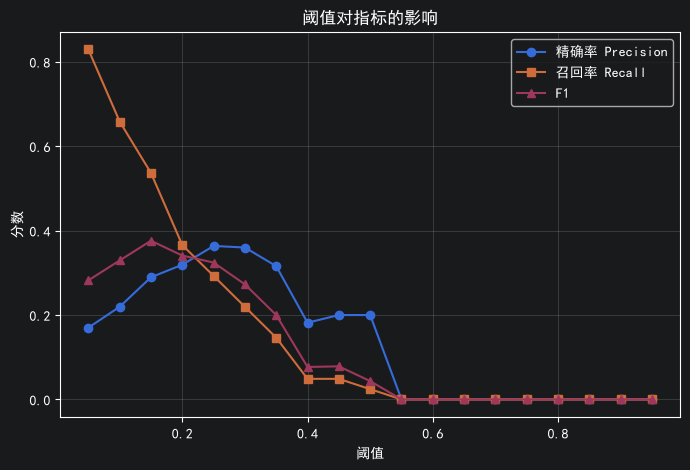

In [9]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

thresholds = np.arange(0.05, 1.0, 0.05)
precisions, recalls, f1s = [], [], []

for t in thresholds:
    y_pred_t = (y_prob >= t).astype(int)
    precisions.append(precision_score(y_test, y_pred_t, zero_division=0))
    recalls.append(recall_score(y_test, y_pred_t, zero_division=0))
    f1s.append(f1_score(y_test, y_pred_t, zero_division=0))

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, 'o-', label='精确率 Precision')
plt.plot(thresholds, recalls, 's-', label='召回率 Recall')
plt.plot(thresholds, f1s, '^-', label='F1')
plt.xlabel('阈值')
plt.ylabel('分数')
plt.title('阈值对指标的影响')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [1]:
#准确：Accuracy = (TP + TN)/All
#精确：Precision = TP/(TP + FP)，结合基础率判断
#召回：Recall = TP/(TP + FN),真患病的人里被找出来的，和阈值挂钩
#F1 = 2 * (Precision * Recall)/(Precision + Recall)
#特异：Specificity = TN / (TN + FP)
#TP = 14 , FP = 10 ,TN = 70 ,FN = 6,All = 100
#Accuracy = (14 + 70)/100
#Precision = 14/(14+10)
#Recall = 14 / (14 + 6)
#F1 = 2*(Prevcision + Recall)/(Precision + Recall)
#Specificity = 70 / (10 + 70)

In [4]:
import numpy as np
from sklearn.metrics import *
y_true = np.array([1]*20 + [0]*80)#20患病+80健康
#构造预测：14个TP + 6个FN + 10个FP + 70个TN,位置不是随便乱写的
y_pred = np.array([1]*14 + [0]*6 + [1]*10 +[0]*70)

print(f"准确率：{accuracy_score(y_true,y_pred):.4f}")
print(f"精确率：{precision_score(y_true,y_pred):.4f}")
print(f"召回率：{recall_score(y_true,y_pred):.4f}")
print(f"F1：   {f1_score(y_true,y_pred):.4f}")
print("\n混淆矩阵")
print(confusion_matrix(y_true,y_pred))

准确率：0.8400
精确率：0.5833
召回率：0.7000
F1：   0.6364

混淆矩阵
[[70 10]
 [ 6 14]]


AUC = 0.7644


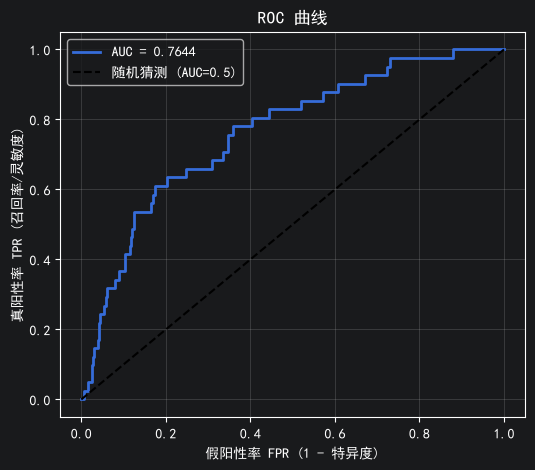

In [3]:
import numpy as np #数组计算工具
import matplotlib.pyplot as plt #画图工具
from sklearn.datasets import make_classification #造模拟数据工具
from sklearn.model_selection import train_test_split #切分数据的工具
from sklearn.linear_model import LogisticRegression #逻辑回归模型
from sklearn.metrics import roc_curve, auc #算ROC曲线工具

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
#造数据，x：(2000,10).y:(2000,)
X, y = make_classification(n_samples=2000, n_features=10, n_informative=5,
                         weights=[0.9, 0.1], random_state=42)
#把2000人分成2段
#X_train,y_train:1600人，这批人学习用（带答案）
#X_test,y_test:400人，考试用（不带答案）
X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.2, random_state=42, stratify=y)
#造一台逻辑回归机器，设置“最多迭代1000轮”
clf = LogisticRegression(max_iter=1000)
#训练，把1600份带答案的练习册喂进去，让机器自己找规律
clf.fit(X_train, y_train)
#让训练好的机器给400个没见过的人打分
#clf.predict_proba(X_test),形状（400，2）的概率表，每行[p(健康),p(患病)]
#[:,1]取第一列，即p（患病）
#y——prob指的是模型对每个人的把握程度，你有多大的概率患病,y_pred是输出结论
y_prob = clf.predict_proba(X_test)[:, 1]
#算ROC和AUC
#FPR = FP / 健康人总数
#TPR = TP / 病人总数
#thresholds 是混淆矩阵
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
print("AUC =", round(roc_auc, 4))

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, linewidth=2, label=f'AUC = {roc_auc:.4f}')
plt.plot([0, 1], [0, 1], 'k--', label='随机猜测 (AUC=0.5)')
plt.xlabel('假阳性率 FPR (1 - 特异度)')
plt.ylabel('真阳性率 TPR (召回率/灵敏度)')
plt.title('ROC 曲线')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [4]:
import torch
import numpy as np
#创建
a = torch.tensor([1.0,2.0,3.0])#打印出来是1.，不是1，因为带小数点表示浮点数，类型是float32，不是numpy的float64
b = torch.zeros(2,3)#造一个全是0的矩阵，2行3列
c = torch.randn(2,3)#造一个2*3的矩阵，每个数从标准正态分布N（0，1）里随机抽取
d = torch.arange(0,10,2)#[0,2,4,6,8]#从0开始，每次加2，到10之前停止
print(a.shape,b.shape,c.shape,d)
#和numpy互转
n = np.array([[1.,2.],[3.,4.]])
t = torch.from_numpy(n)#numpy 转化 tensor
back = t.numpy()#tensor 转化 numpytorch.Size([3]) torch.Size([2, 3]) torch.Size([2, 3]) tensor([0, 2, 4, 6, 8])

torch.Size([3]) torch.Size([2, 3]) torch.Size([2, 3]) tensor([0, 2, 4, 6, 8])


In [13]:
import torch
import numpy as np
x = torch.randn(3,4)
y = torch.randn(4,5)
print((x @ y ).shape) #(3,5)矩阵乘法
print((x + 1).shape)  #广播,给tensor加一个标量，1会自动“铺开”到每个元素上,形状不变，每个元素都＋1，就叫广播
print(x.sum(),x.mean())#聚合,x.sum()所有12个元素加起来，x.mean()所有12个元素的平均值
print(x.T.shape)#转置

torch.Size([3, 5])
torch.Size([3, 4])
tensor(-3.9123) tensor(-0.3260)
torch.Size([4, 3])


In [14]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
x = torch.randn(3,4).to(device)
print(x.device)

cuda:0


In [16]:
import torch
#requires_grad=True表示“这个变量需要求导”
x = torch.tensor(3.0,requires_grad=True)
#前向：随便写个函数
y = x**2 + 3*x +1
#反向：一行搞定
y.backward()
#取梯度
print(x.grad)

tensor(9.)


In [18]:
import torch
x = torch.tensor(2.0,requires_grad=True)
a = x * 3
b = a + 1
c = b ** 2
c.backward()
print(x.grad)
print(2*(3*2+1)*3)

tensor(42.)
42


In [12]:
import torch
x = torch.tensor(2.0,requires_grad=True)
y1 = x ** 2
y1.backward()
print(x.grad)   #4.0
y2 = x ** 3
y2.backward()   #理论上应该打印出来12.0
print(x.grad)
#PyTorch 的梯度是累加的，不是覆盖，所以循环里面必须手动清零

tensor(4.)
tensor(16.)


In [5]:
import torch
x = torch.tensor(2.0,requires_grad=True)
y1 = x ** 2
y1.backward()
print(x.grad)   #4.0
x.grad.zero_()  #当前累加的梯度清零
y2 = x ** 3
y2.backward()   #理论上应该打印出来12.0
print(x.grad)
#PyTorch 的梯度是累加的，不是覆盖，所以循环里面必须手动清零

tensor(4.)
tensor(12.)


In [19]:
import torch
x = torch.tensor(2.0,requires_grad=True)
y = x**2
z = y**2
z.backward()
print(x.grad)#有值
print(y.grad)#是None（中间变量默认不留）

tensor(32.)
None


C:\Users\XiaoZhichuan\AppData\Local\Temp\ipykernel_34416\3721508569.py:7: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\build\aten\src\ATen/core/TensorBody.h:494.)
  print(y.grad)#是None（中间变量默认不留）


In [23]:
import torch
x = torch.tensor(2.0,requires_grad=True)
y = x ** 2
y.retain_grad()
z = y**2
z.backward()
print(x.grad)#有值
print(y.grad)#是None（中间变量默认不留)

tensor(32.)
tensor(8.)


In [28]:
import torch
import numpy as np
torch.manual_seed(42)
#整个循环只有五个动作
#① y_pred = w*x + b        猜
#② loss = ...              打分
#③ loss.backward()         问方向
#④ w -= lr*w.grad          调参数
#⑤ w.grad.zero_()          清零
#造数据
N = 200
x = torch.rand(N)*10
y = 2.5 * x + 1.0 + torch.randn(N)*1.5
#参数：要学的东西，requires_grad=True
w = torch.zeros(1,requires_grad=True)
b = torch.zeros(1,requires_grad=True)
lr = 0.01
for epoch in range(1000):
    #前向
    y_pred = w * x + b
    #损失
    loss = ((y_pred - y)**2).mean()
    #反向--就这一行，梯度自动算好
    loss.backward()
    #更新参数--必须用 no_grad,否则会记进计算图
    with torch.no_grad():
        w -= lr * w.grad#w.grad就是loss.backward()算出来的
        b -= lr * b.grad#y.grad就是loss.backward()算出来的
    #清零梯度
    w.grad.zero_()
    b.grad.zero_()
    if epoch % 200 == 0:
        print(f"epoch {epoch:4d} loss={loss.item():.4f} w={w.item():.4f} b={b.item():.4f}")#.item()就是吧tensor变成普通数字
print(f"\n最终 w={w.item():.4f} b = {b.item():.4f}")

epoch    0 loss=231.4507 w=1.7090 b=0.2673
epoch  200 loss=1.8003 w=2.5455 b=0.9051
epoch  400 loss=1.7818 w=2.5175 b=1.0873
epoch  600 loss=1.7793 w=2.5072 b=1.1540
epoch  800 loss=1.7790 w=2.5034 b=1.1785

最终 w=2.5020 b = 1.1874


In [30]:
import torch
x = torch.tensor(2.0,requires_grad=True)
y = x**3 - 2*x**2 +5
y.backward()
print(x.grad)

tensor(4.)


In [31]:
import torch
x = torch.tensor(1.0,requires_grad=True)
y = torch.tensor(2.0,requires_grad=True)
z = x**2 * y + y**3
z.backward()
print(x.grad)
print(y.grad)

tensor(4.)
tensor(13.)


In [37]:
import torch
w = torch.zeros(1,requires_grad=True)
for epoch in range(100):
    loss = (w * 2-4)**2
    loss.backward()
    with torch.no_grad():
        w -=0.1*w.grad
    print(w.grad)

tensor([-16.])
tensor([-19.2000])
tensor([-7.0400])
tensor([10.7520])
tensor([19.9424])
tensor([13.1789])
tensor([-4.1277])
tensor([-18.1322])
tensor([-17.6309])
tensor([-3.0249])
tensor([14.0010])
tensor([19.8261])
tensor([9.7903])
tensor([-8.0778])
tensor([-19.4836])
tensor([-15.3026])
tensor([1.1205])
tensor([16.6472])
tensor([18.8561])
tensor([5.9801])
tensor([-11.6799])
tensor([-19.9961])
tensor([-12.3153])
tensor([5.2177])
tensor([18.5765])
tensor([17.0742])
tensor([1.9125])
tensor([-14.7792])
tensor([-19.6475])
tensor([-8.7978])
tensor([9.0901])
tensor([19.7060])
tensor([14.5570])
tensor([-2.2375])
tensor([-17.2421])
tensor([-18.4530])
tensor([-4.9015])
tensor([12.5712])
tensor([19.9869])
tensor([11.4131])
tensor([-6.2912])
tensor([-18.9625])
tensor([-16.4638])
tensor([-0.7941])
tensor([15.5109])
tensor([19.4072])
tensor([7.7777])
tensor([-10.0740])
tensor([-19.8665])
tensor([-13.7658])
tensor([3.3475])
tensor([17.7828])
tensor([17.9919])
tensor([3.8074])
tensor([-13.4229])
tens

In [36]:
import torch
w = torch.zeros(1,requires_grad=True)
for epoch in range(100):
    loss = (w * 2-4)**2
    loss.backward()
    with torch.no_grad():
        w -=0.1*w.grad
    w.grad.zero_()
    print(w.grad)

tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])
tensor([0.])

In [6]:
import torch
torch.manual_seed(42)                             # 固定随机种子，结果可复现
# 1. 造数据（和 W6 的 numpy 版同一套设定）
N = 200
x = torch.rand(N) * 10                            # 200 个 0~10 的随机 x
true_w, true_b = 2.5, 1.0                         # 真实答案，最后拿来对答案
y = true_w * x + true_b + torch.randn(N) * 1.5    # 真实直线 + 噪声

# 2. 初始化参数
w = torch.zeros(1, requires_grad=True)            # 要学的参数；True = 需要 autograd 算梯度
b = torch.zeros(1, requires_grad=True)            # 偏置，同样需要梯度
lr = 0.01                                         # 学习率：每一步迈多大
losses = []                                       # 日记本：存每一步的 loss，后面画曲线用

# 3. 训练循环
for epoch in range(1000):
    y_pred = w * x + b                            # ① 前向：先猜一个
    error = y_pred - y                            # 猜的值和真实值差多少
    loss = (error ** 2).mean()                    # ② 损失：误差平方后求平均（MSE）= 当前海拔
    losses.append(loss.item())                    # 记下海拔；.item() 把 tensor 变成普通数字
    loss.backward()                               # ③ 反向：autograd 算出 ∂loss/∂w 和 ∂loss/∂b
    with torch.no_grad():                         # 更新参数的动作不要记进计算图
        w -= lr * w.grad                          # ④ 沿负梯度走一步；W6 手写的 dw 就是 w.grad
        b -= lr * b.grad                          #    b.grad 就是 W6 手写的 db
    w.grad.zero_()                                # ⑤ 清零梯度；不清零下一轮会累加
    b.grad.zero_()
    if epoch % 100 == 0:                          # 每 100 轮打印一次，避免刷屏
        print(f"epoch {epoch:4d}  loss={loss.item():9.4f}  w={w.item():7.4f}  b={b.item():7.4f}")

# 循环结束后，把学到的参数和真实值对比（只打印一次）
print(f"\n真实学到的: w={w.item():.4f} b={b.item():.4f}")
print(f"真实的: w={true_w:.4f} b={true_b:.4f}")


epoch    0  loss= 231.4507  w= 1.7090  b= 0.2673
epoch  100  loss=   1.8373  w= 2.5744  b= 0.7176
epoch  200  loss=   1.8003  w= 2.5455  b= 0.9051
epoch  300  loss=   1.7868  w= 2.5280  b= 1.0186
epoch  400  loss=   1.7818  w= 2.5175  b= 1.0873
epoch  500  loss=   1.7800  w= 2.5111  b= 1.1288
epoch  600  loss=   1.7793  w= 2.5072  b= 1.1540
epoch  700  loss=   1.7791  w= 2.5048  b= 1.1693
epoch  800  loss=   1.7790  w= 2.5034  b= 1.1785
epoch  900  loss=   1.7790  w= 2.5026  b= 1.1841

真实学到的: w=2.5020 b=1.1874
真实的: w=2.5000 b=1.0000


In [8]:
import torch
x = torch.tensor(1.0,requires_grad=True)
y = torch.sin(x) * torch.exp(x)
y.backward()
print(x.grad)

tensor(3.7560)


In [1]:
import torch
import torch.nn as nn
relu = nn.ReLU()
x = torch.tensor([-2.,-1,0,1,2])
print(relu(x))  #tensor([0.,0.,0.,1.,2.])

tensor([0., 0., 0., 1., 2.])


In [2]:
import torch.nn as nn
class MyNet(nn.Module):
    def __init__(self):
        super().__init__()                    # 这行必须有
        self.fc1 = nn.Linear(10, 32)          # 10 -> 32
        self.fc2 = nn.Linear(32, 16)          # 32 -> 16
        self.fc3 = nn.Linear(16, 1)           # 16 -> 1
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x
model = MyNet()
print(model)

MyNet(
  (fc1): Linear(in_features=10, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=16, bias=True)
  (fc3): Linear(in_features=16, out_features=1, bias=True)
  (relu): ReLU()
)


In [3]:
import torch
import torch.nn as nn
import numpy as np
from sklearn.datasets import make_classification #使用make_classification来造数据
torch.manual_seed(42)
#数据
#n_samples=2000,2000个样本
#n_features=10，其中10个特征
#n_informative=5，有用的特征数为5
#random_state=42,随机参数种子42
x,y = make_classification(n_samples=2000,n_features=10,
                          n_informative=5,random_state=42)
#把numpy数组复制成pytorch张量，顺便强制把类型改成float32
#转前：numpy float64
#转后：torch float32
x = torch.tensor(x,dtype=torch.float32)
y = torch.tensor(y,dtype=torch.float32).unsqueeze(1)#(N,)->(N,1)
#模型
class Net(nn.Module):#这是一个pytorch模型，继承后，能被训练，能被保存、能移动到GPU
    def __init__(self):
        super().__init__()  #先启动父类的初始化
        self.net = nn.Sequential(
            nn.Linear(10,32),
            nn.ReLU(),#去掉负数
            nn.Linear(32,16),
            nn.ReLU(),
            nn.Linear(16,1),
            # 注意：这里不加 Sigmoid，输出的是原始分数（logit）
        )
        #把输入x交给前面的self.net处理，然后返回结果
    def forward(self,x):
        return self.net(x)
model = Net()#创建一个实际可用的对象，这一步自动生成了所有权重
#损失和优化器
#BCEWithLogitsLoss = 二分类交叉熵 + 内部自带 Sigmoid，输入是原始分数
#所以网络不用加 Sigmoid，也不用手动 sigmoid 再算 loss
criterion = nn.BCEWithLogitsLoss()#二分类交叉熵（带 Sigmoid）
optimizer = torch.optim.Adam(model.parameters(),lr = 0.01)
#训练
for epoch in range(300):
    y_logit = model(x)              # N×1 的原始分数
    loss = criterion(y_logit,y)      # 内部先 sigmoid 再算交叉熵

    optimizer.zero_grad()            #清梯度
    loss.backward()                  #反向算梯度
    optimizer.step()                 #更新参数

    if epoch % 50 ==0:
        # 查准确率要先把分数转成概率再和 0.5 比
        acc = ((torch.sigmoid(y_logit) > 0.5).float() == y).float().mean()
        print(f"epoch {epoch:3d}  loss={loss.item():.4f}  acc={acc.item():.4f}")


epoch   0  loss=0.7135  acc=0.3290
epoch  50  loss=0.1759  acc=0.9280
epoch 100  loss=0.1053  acc=0.9640
epoch 150  loss=0.0621  acc=0.9830
epoch 200  loss=0.0377  acc=0.9910
epoch 250  loss=0.0227  acc=0.9970


In [4]:
import torch
import torch.nn as nn
class MyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784,128)
        self.fc2 = nn.Linear(128,64)
        self.fc3 = nn.Linear(64,10)
        self.relu = nn.ReLU()
    def forward(self,x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)
model = MyNet()#造网络
#参数量
total = sum(p.numel() for p in model.parameters())#数参数，把模型可训练的张量一个个列出来
print("总参数:",total)
for name,p in model.named_parameters():
    print(f"{name}:{tuple(p.shape)} {p.numel()}")

x = torch.randn(32,784)
print("输出形状:",model(x).shape)

总参数: 109386
fc1.weight:(128, 784) 100352
fc1.bias:(128,) 128
fc2.weight:(64, 128) 8192
fc2.bias:(64,) 64
fc3.weight:(10, 64) 640
fc3.bias:(10,) 10
输出形状: torch.Size([32, 10])


In [1]:
import torch
import torch.nn as nn
from sklearn.datasets import make_moons

x,y = make_moons(n_samples=1000,noise=0.1,random_state=42)
x = torch.tensor(x,dtype=torch.float32)
y = torch.tensor(y,dtype=torch.float32).unsqueeze(1)

class withReLU(nn.Module):
    def __init__(self):
        super().__init__()
        #self.net是名字
        #nn.Sequential()是一个按顺序执行的容器
        self.net = nn.Sequential(
            nn.Linear(2,32),
            nn.ReLU(),
            nn.Linear(32,32),
            nn.ReLU(),
            nn.Linear(32,1),
            nn.Sigmoid()
        )

    def forward(self,x):
        return self.net(x)

class NoReLU(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2,32),
            nn.Linear(32,32),
            nn.Linear(32,1),
            nn.Sigmoid()
        )
    def forward(self,x):
        return self.net(x)

for name,cls in [('有ReLu',withReLU),('无ReLU',NoReLU)]:
    model = cls()
    opt = torch.optim.Adam(model.parameters(),lr=0.01)
    crit = nn.BCELoss()
    for _ in range(300):
        opt.zero_grad()
        loss = crit(model(x),y)
        loss.backward()
        opt.step()
    # 算准确率：网络输出(1000,1)的概率 > 0.5 判为正类
    # model(x)        网络输出 0~1 的概率
    # > 0.5           大于 0.5 为 True，否则 False
    # .float()        True->1.0 False->0.0，变成预测标签
    # == y            和真实标签比较，对的是 True
    # .float()        再变 1.0/0.0
    # .mean()         求平均 = 答对的比例 = 准确率
    acc = ((model(x) > 0.5).float() == y).float().mean()
    print(f"{name}: 准确率 = {acc.item():.4f}")


有ReLu: 准确率 = 1.0000
无ReLU: 准确率 = 0.8780


SGD  (lr=0.01) : 最终 loss=0.4894  acc=0.8240
Adam (lr=0.001): 最终 loss=0.1013  acc=0.9660


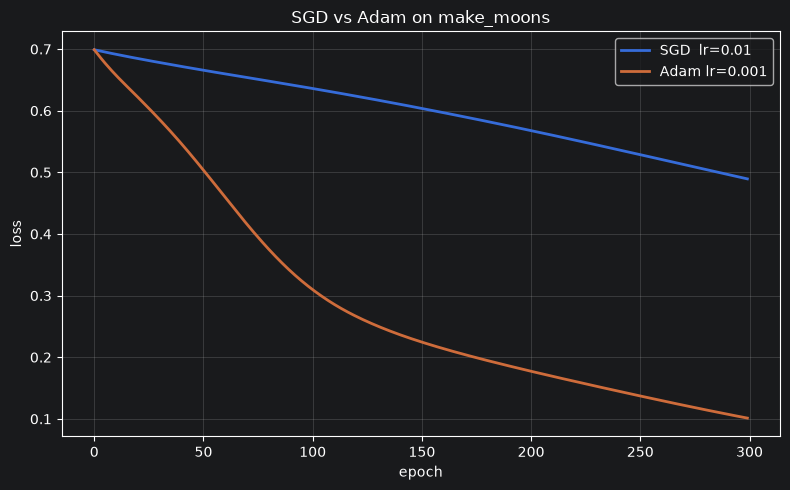

In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# 造数据
torch.manual_seed(42)
X, y = make_moons(n_samples=1000, noise=0.1, random_state=42)
X = torch.tensor(X, dtype=torch.float32)                 # numpy数组变成Tensor，类型改为float32
y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)    # (N,) -> (N,1)

# 设定网络结构
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            # 末层不加 Sigmoid：后面用 BCEWithLogitsLoss，它内部自带 Sigmoid
        )

    def forward(self, x):
        return self.net(x)

def train(optimizer_name, lr, epochs=300):
    torch.manual_seed(42)                 # 两组从同一个初始权重出发
    model = Net()
    criterion = nn.BCEWithLogitsLoss()    # 二分类交叉熵（内部自带 Sigmoid）

    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    losses = []   # 创建一个空本子，把每一步的loss都保留下来
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model(X)                 # 大写 X
        loss = criterion(y_pred, y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    # 网络输出是 logit（原始分数），logit > 0 等价于 sigmoid(logit) > 0.5
    #with torch.no_grad():接下来这段只做计算，不用改变任何东西，这样不会在内存里囤一大堆中间结果
    with torch.no_grad():
        #.item()把张量变成普通数字，因为要用于画图，画图需要使用数字
        acc = ((model(X) > 0).float() == y).float().mean().item()
    return losses, acc

# 跑两组
loss_adam, acc_adam = train("Adam", lr=0.001)
print(f"SGD  (lr=0.01) : 最终 loss={loss_sgd[-1]:.4f}  acc={acc_sgd:.4f}")
print(f"Adam (lr=0.001): 最终 loss={loss_adam[-1]:.4f}  acc={acc_adam:.4f}")

# 画图
plt.figure(figsize=(8, 5))               # figsize 必须是 (宽, 高) 两个数
plt.plot(loss_sgd,  label="SGD  lr=0.01",  linewidth=2)
plt.plot(loss_adam, label="Adam lr=0.001", linewidth=2)
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("SGD vs Adam on make_moons")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


                训练集acc   测试集acc   差距
不加Dropout      1.0000      0.9722      +0.0278
加Dropout0.3    0.9992      0.9815      +0.0177


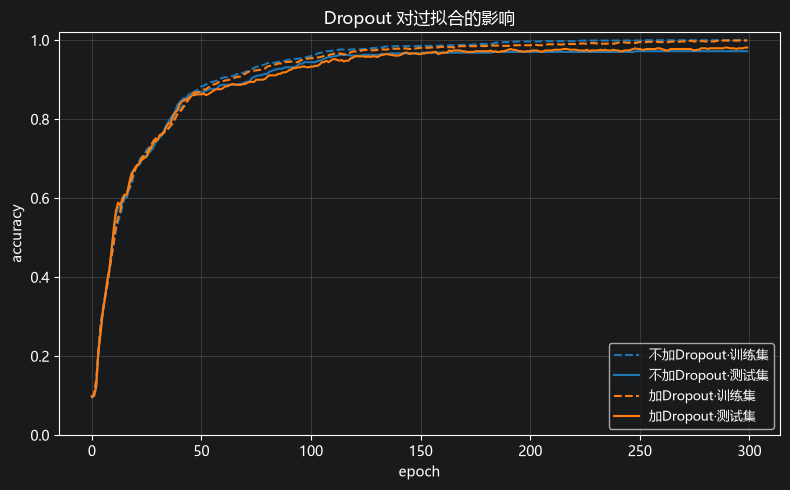

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

#造数据
#这是sklearn自带的手写数字数据集，不需要下载，装好sklearn就在本地
d = load_digits()
#/16.0，把0~16压到0~1之间，神经网络读0~1之间的的输入最敏感，直接喂数字，数字跨度太大会让训练不稳定
X = torch.tensor(d.data / 16.0,dtype=torch.float32)#numpy数组默认是float64类型，pytorch默认要float32
y = torch.tensor(d.target,dtype=torch.long)
X_tr, X_te, y_tr, y_te = train_test_split(X, y,test_size=0.3,
                                          random_state=42,stratify=y)
#构建神经网络,MyNet
class MyNet(nn.Module):
    def __init__(self,use_dropout):
        super().__init__()
        self.fc1 = nn.Linear(64,128)
        self.fc2 = nn.Linear(128,64)
        self.fc3 = nn.Linear(64,10)
        self.relu = nn.ReLU()
        #随机丢弃30%的神经元，防止过拟合
        self.dropout = nn.Dropout(0.3)
        self.use_dropout = use_dropout
    def forward(self,x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        if self.use_dropout:
            x = self.dropout(x)#fc2之后、fc3之前丢弃
        return self.fc3(x)
#算准确率：10个分数里最大的那个是预测类别，和真实标签比，对的占多少
@torch.no_grad()
def acc(model,X,y):
    #算分关掉Dropout
    model.eval()
    #.item()就是把pytorch中的张量变成普通数字
    return (model(X).argmax(dim=1) == y).float().mean().item()
#训练一次，返回每一步的训练集/测试集准确率
def train(use_dropout, epochs=300, lr=1e-3):
    #两组起点相同
    torch.manual_seed(0)
    model = MyNet(use_dropout)
    opt = torch.optim.Adam(model.parameters(),lr=lr)
    crit = nn.CrossEntropyLoss()
    tr_hist, te_hist = [], []
    for _ in range(epochs):
        model.train()                    #训练时打开Dropout
        opt.zero_grad()
        loss = crit(model(X_tr), y_tr)
        loss.backward()
        opt.step()
        tr_hist.append(acc(model, X_tr, y_tr))
        te_hist.append(acc(model, X_te, y_te))
    return tr_hist, te_hist
#跑两组：不加Dropout vs 加Dropout
tr_no, te_no = train(use_dropout=False)
tr_yes, te_yes = train(use_dropout=True)
print("                训练集acc   测试集acc   差距")
for name, tr, te in [("不加Dropout", tr_no, te_no), ("加Dropout0.3", tr_yes, te_yes)]:
    print(f"{name:12s}   {tr[-1]:.4f}      {te[-1]:.4f}      {tr[-1] - te[-1]:+.4f}")
#画图：虚线是训练集，实线是测试集，两条线挨得越近，说明越没有过拟合
plt.figure(figsize=(8, 5))
plt.plot(tr_no, "--", color="tab:blue", label="不加Dropout·训练集")
plt.plot(te_no, "-", color="tab:blue", label="不加Dropout·测试集")
plt.plot(tr_yes, "--", color="tab:orange", label="加Dropout·训练集")
plt.plot(te_yes, "-", color="tab:orange", label="加Dropout·测试集")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("Dropout 对过拟合的影响")
plt.ylim(0, 1.02)
plt.legend(fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [2]:
import torch
import torch.nn as nn
#一张1通道5*5的“图”
x =  torch.tensor([[[
    [1.,1.,1.,0.,0.],
    [1.,1.,1.,0.,0.],
    [1.,1.,1.,0.,0.],
    [0.,0.,0.,1.,1.],
    [0.,0.,0.,1.,1.],
]]])
#in_channels，输入是1个通道（灰度图）
#out_channels,用1个核
#kernel_size,核是3*3
#padding=0,不补零，padding=1,补零，就是在图的周围补上一圈0，让5*5的图片变成7*7，所以扫完输出又变成5*5，图片不会缩小,公式:输出=输入-核+1+2*padding
conv = nn.Conv2d(in_channels=1,out_channels=1,kernel_size=3,padding=0)
#conb.weight.shape就是（输出通道，输入通道，高，宽）
print(conv.weight.shape)#卷积核的形,(输出通道，输入通道，核高，核宽)
out = conv(x)
print(out.shape)#输出数据的形状，（几张图，输出通道，高，宽）

torch.Size([1, 1, 3, 3])
torch.Size([1, 1, 3, 3])


尺寸公式：输出=floor((输入 - 窗口) / 步长) + 1，默认步长=窗口=2

In [1]:
import torch
import torch.nn.functional as F

x = torch.tensor([[
    [[1.,2.,3.],[4.,5.,6.],[7.,8.,9.]],#通道0
    [[1.,1.,1.],[1.,1.,1.],[1.,1.,1.]],#通道1
]])

w_a = torch.tensor([[[[1.,0.,0.],[0.,1.,0.],[0.,0.,1.]],
                     [[0.,0.,0.],[0.,0.,0.],[0.,0.,0.]]]])
print(F.conv2d(x,w_a).item())#.item()把tensor张量变成数字
w_b = torch.tensor([[[[1.,0.,0.],[0.,1.,0.],[0.,0.,1.]],
                     [[1.,1.,1.],[1.,1.,1.],[1.,1.,1.]]]])
print(F.conv2d(x, w_b).item())

15.0
24.0


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# -------------------------------------------------
# 1️⃣ 固定随机种子 & 选取计算设备（GPU or CPU）
# -------------------------------------------------
torch.manual_seed(42)                     # 保证每次跑得到相同的初始化权重
device = "cuda" if torch.cuda.is_available() else "cpu"  # 有显卡就用 GPU，否则用 CPU

# -------------------------------------------------
# 2️⃣ 数据预处理 & 加载（已下载到本地，关闭网络下载）
# -------------------------------------------------
transform = transforms.ToTensor()  # 把 PIL 图片转为 Tensor，并把像素值 0~255 缩放到 0~1
# 注意变量名必须是 transform（单数），否则会把 torchvision 模块覆盖掉
train_set = datasets.MNIST(
    './data',            # 数据根目录，内部会在 ./data/MNIST/raw/ 找到解压好的文件
    train=True,
    download=False,      # 已经手动下载好，这里不再尝试网络请求
    transform=transform)

test_set = datasets.MNIST(
    './data',
    train=False,
    download=False,
    transform=transform)

# DataLoader 会把数据划分成 mini‑batch，shuffle=True 打乱训练顺序
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=64, shuffle=False)

# -------------------------------------------------
# 3️⃣ 定义卷积神经网络（CNN）
# -------------------------------------------------
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        # ---------- 特征提取层 ----------
        self.features = nn.Sequential(
            # 1 通道 → 32 通道，kernel=3，padding=1 保持特征图尺寸不变 (28×28)
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),          # ↓尺寸减半 → 14×14

            # 32 通道 → 64 通道，同理保持尺寸
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)           # ↓尺寸再减半 → 7×7
        )
        # ---------- 分类器 ----------
        self.classifier = nn.Sequential(
            nn.Flatten(),               # 将 (N,64,7,7) 拉平成 (N,3136)
            nn.Linear(3136, 128),
            nn.ReLU(),
            nn.Dropout(0.5),            # 训练时随机丢掉 50% 神经元，防止过拟合
            nn.Linear(128, 10)         # 输出 10 类的 logits（未经过 softmax）
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# -------------------------------------------------
# 4️⃣ 实例化模型、打印结构、统计参数量
# -------------------------------------------------
model = CNN().to(device)               # 把模型搬到前面选好的 device（GPU/CPU）
print(model)                           # 查看网络层次结构
print("参数量：", sum(p.numel() for p in model.parameters()))  # 约 42 万，可在显存中轻松容纳

# -------------------------------------------------
# 5️⃣ 损失函数 & 优化器
# -------------------------------------------------
criterion = nn.CrossEntropyLoss()      # 多分类交叉熵，内部会自动做 softmax
optimizer = optim.Adam(model.parameters(), lr=1e-3)  # Adam 自适应学习率，收敛快

# -------------------------------------------------
# 6️⃣ 训练 & 测试循环（这里跑 3 个 epoch 作示例）
# -------------------------------------------------
for epoch in range(3):
    # ----- 训练阶段 -----
    model.train()                        # 打开 dropout、BatchNorm 等训练行为
    running_loss = 0.0
    for xb, yb in train_loader:          # xb: [B,1,28,28]，yb: [B]（标签 0~9）
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()            # 清除上一步累计的梯度
        loss = criterion(model(xb), yb)  # 前向 + 计算交叉熵 loss
        loss.backward()                  # 反向传播，自动计算每个参数的梯度
        optimizer.step()                 # 根据 Adam 规则更新参数
        running_loss += loss.item()

    # ----- 测试阶段 -----
    model.eval()                         # 关闭 dropout，使用推理模式
    correct = total = 0
    with torch.no_grad():                # 评估时不需要梯度，节省显存和计算
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb).argmax(1)   # 取 logits 最大的索引作为预测类别
            correct += (preds == yb).sum().item()
            total   += yb.size(0)

    # ----- 本轮结果 -----
    print(f"Epoch {epoch+1}  loss={running_loss/len(train_loader):.4f}  "
          f"测试准确率={correct/total:.4f}")


CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
参数量： 421642
Epoch 1  loss=0.3001  测试准确率=0.9756
Epoch 2  loss=0.1077  测试准确率=0.9859
Epoch 3  loss=0.0802  测试准确率=0.9880


[Epoch 1] loss=0.3002
[Epoch 2] loss=0.1085
[Epoch 3] loss=0.0832


C:\Users\XiaoZhichuan\AppData\Local\Temp\ipykernel_38808\1154606994.py:70: UserWarning: Glyph 31532 (\N{CJK UNIFIED IDEOGRAPH-7B2C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()  # 自动调整间距
C:\Users\XiaoZhichuan\AppData\Local\Temp\ipykernel_38808\1154606994.py:70: UserWarning: Glyph 23618 (\N{CJK UNIFIED IDEOGRAPH-5C42}) missing from font(s) DejaVu Sans.
  plt.tight_layout()  # 自动调整间距
C:\Users\XiaoZhichuan\AppData\Local\Temp\ipykernel_38808\1154606994.py:70: UserWarning: Glyph 21367 (\N{CJK UNIFIED IDEOGRAPH-5377}) missing from font(s) DejaVu Sans.
  plt.tight_layout()  # 自动调整间距
C:\Users\XiaoZhichuan\AppData\Local\Temp\ipykernel_38808\1154606994.py:70: UserWarning: Glyph 31215 (\N{CJK UNIFIED IDEOGRAPH-79EF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()  # 自动调整间距
C:\Users\XiaoZhichuan\AppData\Local\Temp\ipykernel_38808\1154606994.py:70: UserWarning: Glyph 26680 (\N{CJK UNIFIED IDEOGRAPH-6838}) missing from font(s) DejaVu Sans.
  plt.tight_layout()  # 自动调整间距
C:\Users\X

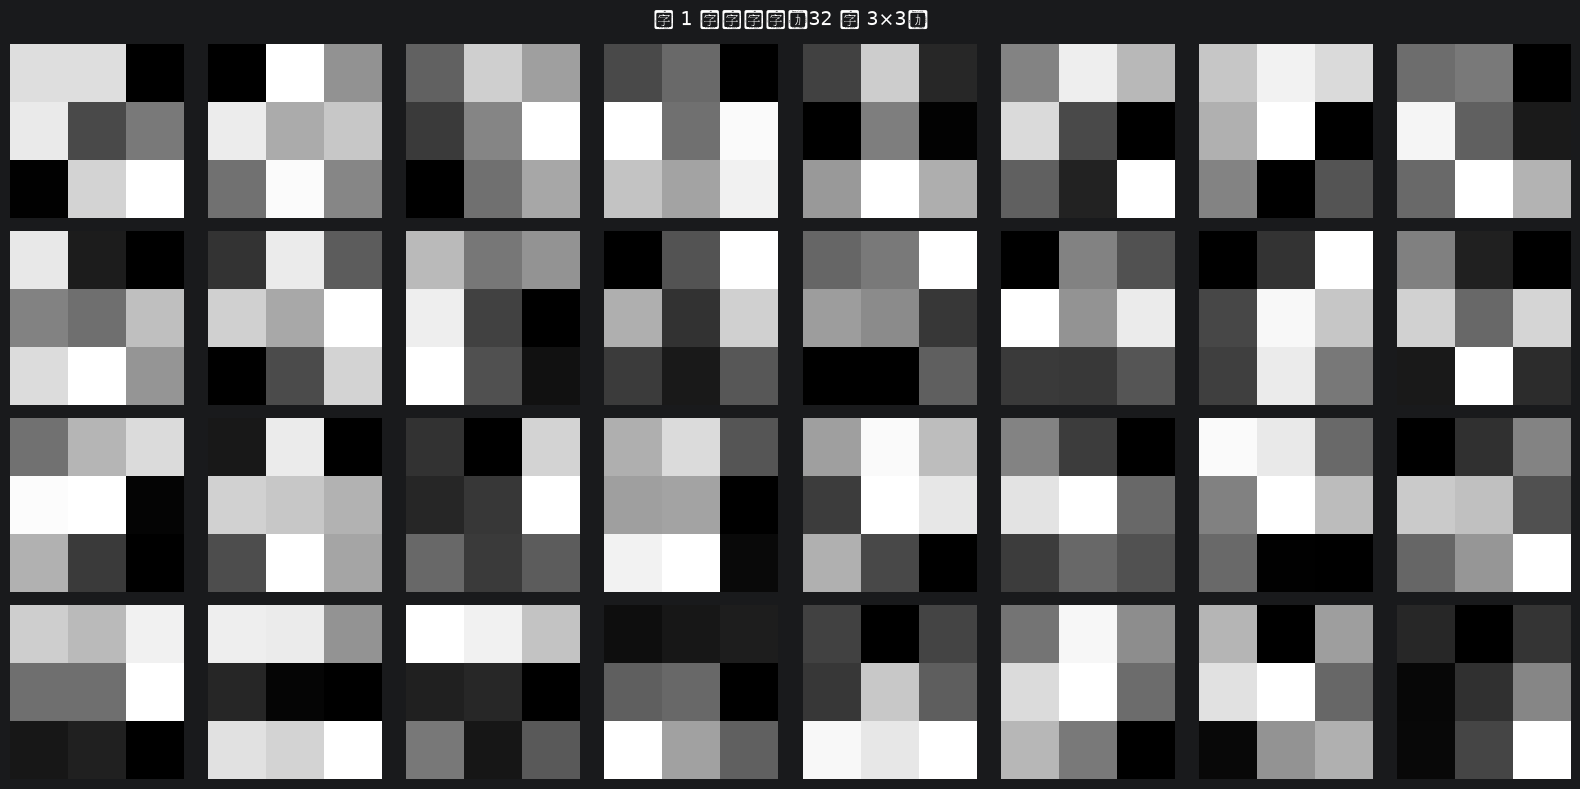

C:\Users\XiaoZhichuan\AppData\Local\Temp\ipykernel_38808\1154606994.py:91: UserWarning: Glyph 31532 (\N{CJK UNIFIED IDEOGRAPH-7B2C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()  # 调整间距
C:\Users\XiaoZhichuan\AppData\Local\Temp\ipykernel_38808\1154606994.py:91: UserWarning: Glyph 24352 (\N{CJK UNIFIED IDEOGRAPH-5F20}) missing from font(s) DejaVu Sans.
  plt.tight_layout()  # 调整间距
C:\Users\XiaoZhichuan\AppData\Local\Temp\ipykernel_38808\1154606994.py:91: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()  # 调整间距
C:\Users\XiaoZhichuan\AppData\Local\Temp\ipykernel_38808\1154606994.py:91: UserWarning: Glyph 35797 (\N{CJK UNIFIED IDEOGRAPH-8BD5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()  # 调整间距
C:\Users\XiaoZhichuan\AppData\Local\Temp\ipykernel_38808\1154606994.py:91: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()  # 调整间距
C:\Users\XiaoZhichua

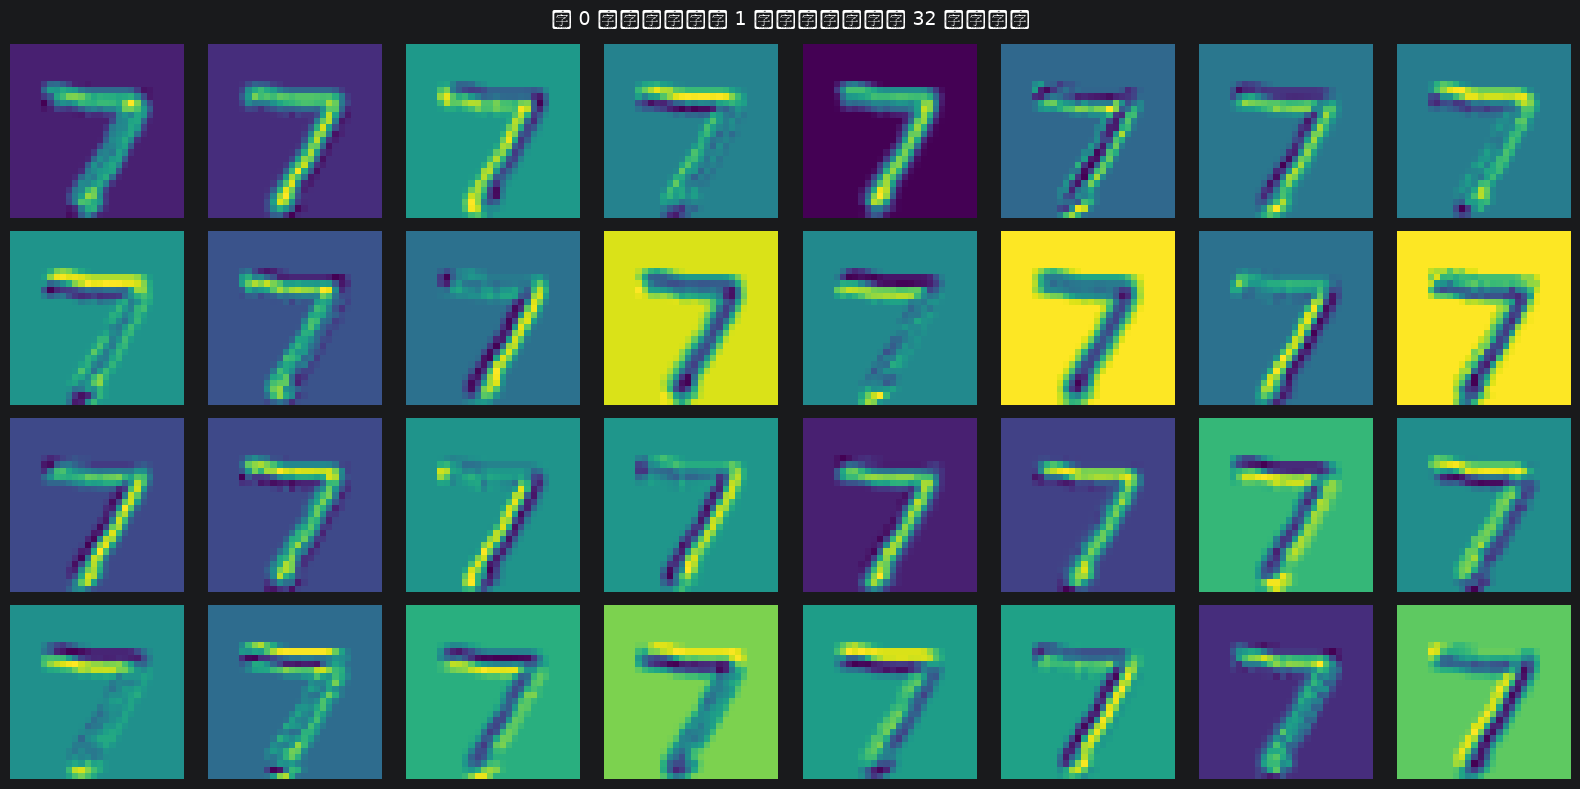

In [5]:
#必要的import
import torch  # 张量/模型核心库
import torch.nn as nn  # 神经网络层
import torch.optim as optim  # 优化器
from torchvision import datasets, transforms  # 数据集与预处理
from torch.utils.data import DataLoader  # 批量加载数据
import matplotlib.pyplot as plt  # 画图

#环境、数据
torch.manual_seed(42)  # 固定随机种子
device = "cuda" if torch.cuda.is_available() else "cpu"  # 有 GPU 就用 GPU

transform = transforms.ToTensor()  # 图片转张量并归一化到 0~1
train_set = datasets.MNIST('./data', train=True, download=False, transform=transform)  # 训练集
test_set = datasets.MNIST('./data', train=False, download=False, transform=transform)  # 测试集

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)  # 训练批次，打乱
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)  # 测试批次，不打乱

class CNN(nn.Module):  # 定义 CNN
    def __init__(self):  # 初始化
        super().__init__()  # 初始化父类
        self.features = nn.Sequential(  # 特征提取部分
            nn.Conv2d(1, 32, 3, padding=1),  # 1→32 通道，3×3 卷积
            nn.ReLU(),  # 激活函数，保留正数
            nn.MaxPool2d(2),  # 2×2 池化，尺寸减半
            nn.Conv2d(32, 64, 3, padding=1),  # 32→64 通道
            nn.ReLU(),  # 激活
            nn.MaxPool2d(2)  # 再池化，尺寸再减半
        )
        self.classifier = nn.Sequential(  # 分类部分
            nn.Flatten(),  # 拉平特征图
            nn.Linear(3136, 128),  # 全连接层
            nn.ReLU(),  # 激活
            nn.Dropout(0.5),  # 随机丢弃 50%，防过拟合
            nn.Linear(128, 10)  # 输出 10 类
        )
    def forward(self, x):  # 前向传播
        x = self.features(x)  # 先提特征
        return self.classifier(x)  # 再分类

model = CNN().to(device)  # 创建模型并放到设备
criterion = nn.CrossEntropyLoss()  # 多分类交叉熵损失
optimizer = optim.Adam(model.parameters(), lr=1e-3)  # Adam 优化器

#训练
model.train()  # 训练模式
for epoch in range(3):  # 训练 3 轮
    running_loss = 0.0  # 累计损失
    for xb, yb in train_loader:  # 逐批读取
        xb, yb = xb.to(device), yb.to(device)  # 数据放到设备
        optimizer.zero_grad()  # 清空梯度
        loss = criterion(model(xb), yb)  # 前向 + 计算损失
        loss.backward()  # 反向传播
        optimizer.step()  # 更新参数
        running_loss += loss.item()  # 累加损失
    print(f"[Epoch {epoch+1}] loss={running_loss/len(train_loader):.4f}")  # 打印平均损失

#可视化卷积
model.eval()  # 评估模式
kernels = model.features[0].weight.detach().cpu()  # 取出第一层卷积核
kernels_norm = (kernels - kernels.min()) / (kernels.max() - kernels.min() + 1e-8)  # 归一化 到 0~1

plt.figure(figsize=(16, 8))  # 新建画布
for i in range(32):  # 画 32 个核
    ax = plt.subplot(4, 8, i + 1)  # 4×8 网格
    ax.imshow(kernels_norm[i, 0].numpy(), cmap='gray')  # 显示第 i 个核
    ax.axis('off')  # 隐藏坐标轴
plt.suptitle('第 1 层卷积核（32 个 3×3）', fontsize=14)  # 标题
plt.tight_layout()  # 自动调整间距
plt.show()  # 显示

xb, _ = next(iter(test_loader))  # 取一个测试批次
xb = xb.to(device)  # 放到设备

model.eval()  # 评估模式
with torch.no_grad():  # 不求梯度
    feats = model.features[0](xb)  # 第一层卷积输出

feats_norm = torch.zeros_like(feats)  # 存放归一化结果
for c in range(feats.shape[1]):  # 按通道归一化
    ch = feats[:, c]  # 取一个通道
    feats_norm[:, c] = (ch - ch.min()) / (ch.max() - ch.min() + 1e-8)  # 归一化

plt.figure(figsize=(16, 8))  # 新建画布
for i in range(32):  # 画 32 张特征图
    ax = plt.subplot(4, 8, i + 1)  # 4×8 网格
    ax.imshow(feats_norm[0, i].cpu().numpy(), cmap='viridis')  # 显示第 i 张
    ax.axis('off')  # 隐藏坐标轴
plt.suptitle('第 0 张测试图经第 1 层卷积后得到的 32 张特征图', fontsize=14)  # 标题
plt.tight_layout()  # 调整间距
plt.show()  # 显示


In [1]:
import pydicom, medmnist, seaborn
print(pydicom.__version__, medmnist.__version__, seaborn.__version__)

3.0.2 3.0.2 0.13.2


In [5]:
import pydicom                                  # 读 .dcm 文件的库
import numpy as np                              # 数组库
import matplotlib.pyplot as plt                 # 画图库

plt.rcParams['font.sans-serif'] = ['SimHei']    # 中文字体，标题不显示方块
plt.rcParams['axes.unicode_minus'] = False      # 负号正常显示

# 讲义里的 E:\某病人CT\IM0001.dcm 只是示意路径，你电脑上没有这个文件，所以报 FileNotFoundError。
# pydicom 自带一张真实 CT，用 get_testdata_file 取，任何电脑都能跑：
from pydicom.data import get_testdata_file      # 取 pydicom 自带示例文件
ds = pydicom.dcmread(get_testdata_file("CT_small.dcm"))   # 读入一张真实 CT

# 以后拿到自己的 .dcm 文件时，把上面两行换成（路径必须真实存在）：
# ds = pydicom.dcmread(r"E:\真实路径\xxx.dcm")

print("模态:", ds.Modality)                     # CT / MR ...
print("图像尺寸:", ds.Rows, "x", ds.Columns)     # 128 x 128
print("像素间距:", ds.PixelSpacing)              # 每个像素多少毫米
print("层厚:", getattr(ds, 'SliceThickness', '该文件没有'))   # 标签可能缺失，getattr 防崩
print("位深:", ds.BitsStored)                   # 存储位数


模态: CT
图像尺寸: 128 x 128
像素间距: [0.661468, 0.661468]
层厚: 5.000000
位深: 16


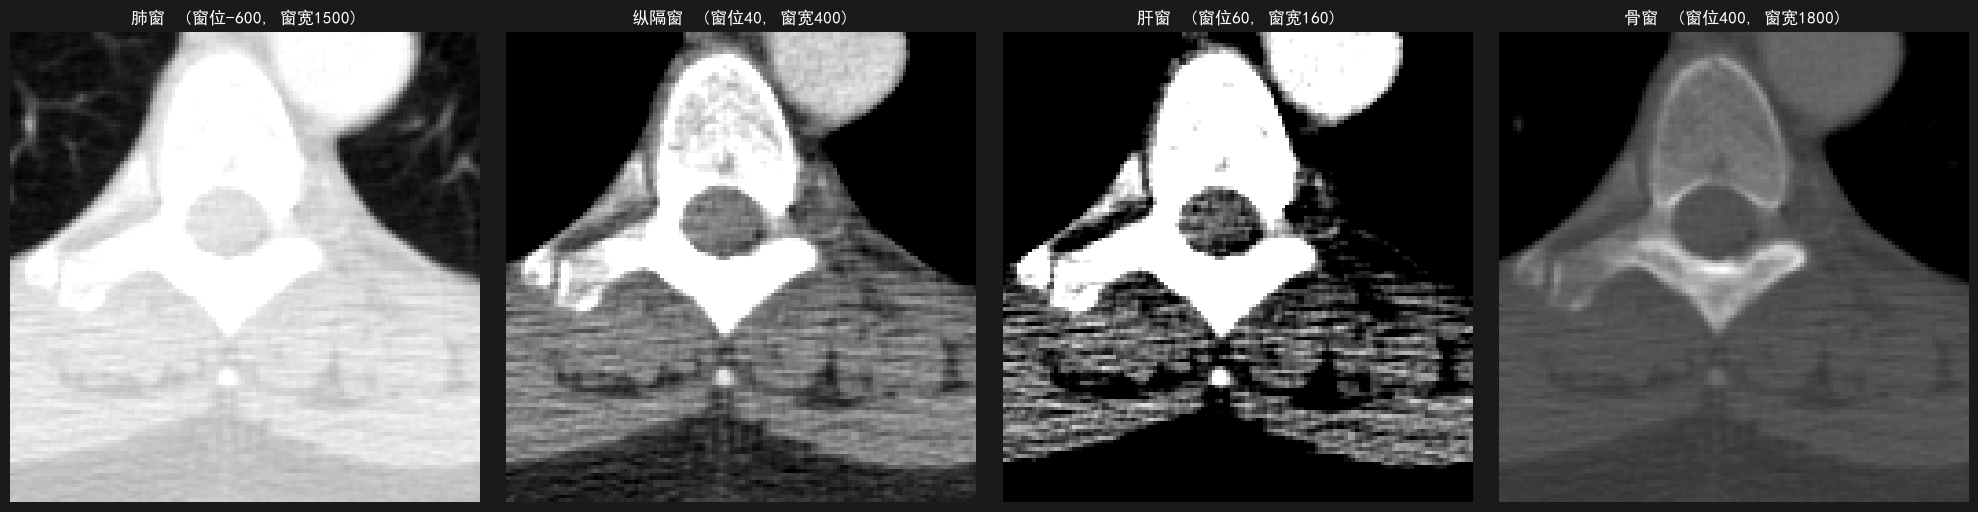

In [7]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']          # 中文标题不显示方块
plt.rcParams['axes.unicode_minus'] = False            # 负号正常显示

# ① 原始像素值 → HU 值
pixels = ds.pixel_array                               # 原始整数，不是 HU
slope = float(getattr(ds, 'RescaleSlope', 1))         # 斜率
intercept = float(getattr(ds, 'RescaleIntercept', 0)) # 截距
hu = pixels.astype(np.float32) * slope + intercept    # 换算成


# ② 窗宽窗位函数（讲义第五节）
def apply_window(img_hu, center, width):
  low  = center - width / 2                         # 窗下边界
  high = center + width / 2                         # 窗上边界
  img = np.clip(img_hu, low, high)                  # 窗外压到边界
  img = (img - low) / (high - low) * 255            # 窗内拉到 0~255
  return img.astype(np.uint8)                       # 转成屏幕整数

# ③ 四套窗，一行四张图
windows = {
  '肺窗':   (-600, 1500),
  '纵隔窗': (40,   400),
  '肝窗':   (60,   160),
  '骨窗':   (400,  1800),
}
fig, axes = plt.subplots(1, 4, figsize=(20, 5))       # 1 行 4 个画布
for ax, (name, (c, w)) in zip(axes, windows.items()): # 每个画布配一套窗
  ax.imshow(apply_window(hu, c, w), cmap='gray')    # 套窗后显示
  ax.set_title(f'{name}  (窗位{c}, 窗宽{w})')
  ax.axis('off')                                    # 隐藏坐标刻度
plt.tight_layout()
plt.show()

In [13]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import transforms
import medmnist
from medmnist import INFO
from pathlib import Path

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

ROOT = Path(r'E:\AI学习\练习代码\data\medmnist')   # 数据放 E 盘，不占 C 盘
ROOT.mkdir(parents=True, exist_ok=True)            # 目录要自己建

#选数据集
data_flag = 'pneumoniamnist'#肺炎胸片
info = INFO[data_flag]
DataClass = getattr(medmnist,info['python_class'])
n_classes = len(info['label'])

print("任务:", info['task'])
print("类别:", info['label'])
print("通道数:", info['n_channels'])

#加载
# PIL Image  ──ToTensor──▶  torch.Tensor  ──▶  能喂给网络
transform = transforms.Compose([transforms.ToTensor()])
train_set = DataClass(split='train',transform=transform,download=True,root=str(ROOT))
val_set = DataClass(split='val',transform=transform,download=True,root=str(ROOT))
test_set = DataClass(split='test',transform=transform,download=True,root=str(ROOT))

print(f"训练{len(train_set)} 验证{len(val_set)} 测试{len(test_set)}")
#shuffle,模型每看一批就要改一点参数，所以训练集要True，验证集和测试集要False
train_loader = DataLoader(train_set,batch_size=64,shuffle=True)
val_loader = DataLoader(val_set,batch_size=64,shuffle=False)
test_loader = DataLoader(test_set,batch_size=64,shuffle=False)

#看一眼形状
x,y = train_set[0]
#x.shape=[1,28,28],第一个指定的是颜色，1是灰度，3是彩色，28，28是这副图像的尺寸，宽*高
print("单张:",x.shape,"标签:",y.shape,"值:",y)

#网络
class SmallCNN(nn.Module):
    def __init__(self,in_ch,n_cls):
        super().__init__()
        #features负责从图像中提取特征，classifier负责从特征处去判断
        self.features = nn.Sequential(
            #in_ch就是用图像默认的色度输入进去，如果是灰度图是1，如果是色彩图是3
            nn.Conv2d(in_ch,16,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16,32,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            #Flatten把多维参数拉成一维数组
            nn.Flatten(),
            nn.Linear(32*7*7,64),
            nn.ReLU(),
            nn.Linear(64,n_cls),
        )

    def forward(self,x):
        return self.classifier(self.features(x))

#训练准备
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("使用设备:",device)

model = SmallCNN(info['n_channels'],n_classes).to(device)
print("参数量：",sum(p.numel() for p in model.parameters()))
#CrossEntropyLoss(),衡量错误有多离谱
criterion = nn.CrossEntropyLoss()
#optimizer,按照损失去调整
optimizer = optim.Adam(model.parameters(),lr=1e-3)
#训练
for epoch in range(5):
    model.train()#切换到“训练模式”
    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.squeeze().long().to(device)

        optimizer.zero_grad()
        loss = criterion(model(xb),yb)
        loss.backward()
        optimizer.step()

    model.eval()#切换到“考试模式”
    correct = total = 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.squeeze().long().to(device)
            pred = model(xb).argmax(1)
            correct += (pred == yb).sum().item()
            total += yb.size(0)

    print(f"Epoch{epoch+1} 验证准确率 = {correct/total:.4f}")

任务: binary-class
类别: {'0': 'normal', '1': 'pneumonia'}
通道数: 1
训练4708 验证524 测试624
单张: torch.Size([1, 28, 28]) 标签: (1,) 值: [1]
使用设备: cuda
参数量： 105346
Epoch1 验证准确率 = 0.7424
Epoch2 验证准确率 = 0.9160
Epoch3 验证准确率 = 0.9504
Epoch4 验证准确率 = 0.9485
Epoch5 验证准确率 = 0.9504


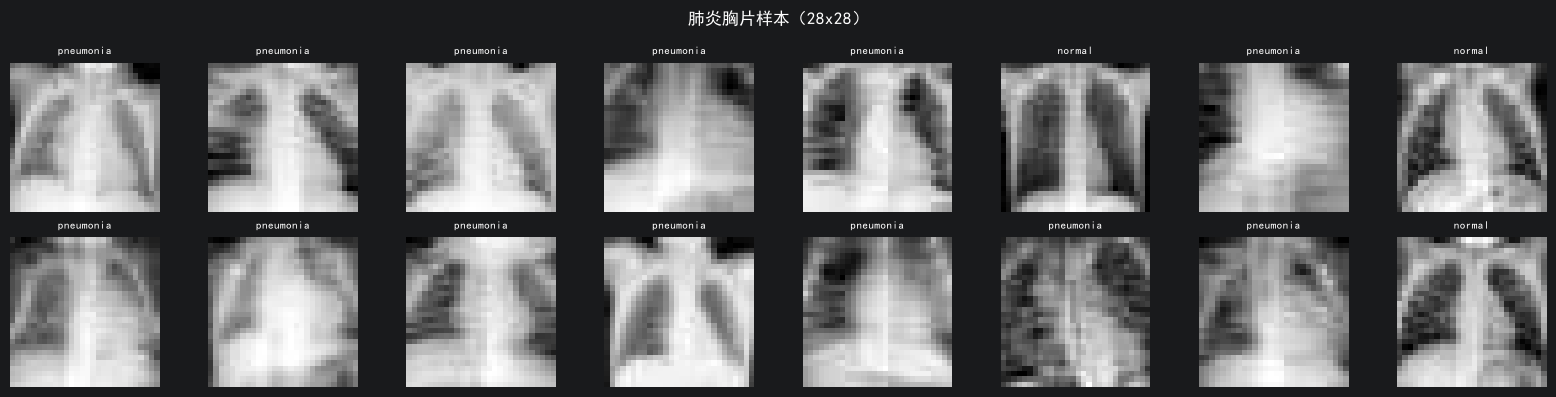

In [14]:
# 看看图像长什么样（讲义 4-1 第八节）
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.flat):
    img, lab = train_set[i]
    ax.imshow(img.squeeze(), cmap='gray')   # (1,28,28) -> (28,28)
    ax.set_title(info['label'][str(lab.squeeze().item())], fontsize=8)
    ax.axis('off')
plt.suptitle('肺炎胸片样本（28x28）')
plt.tight_layout()
plt.show()


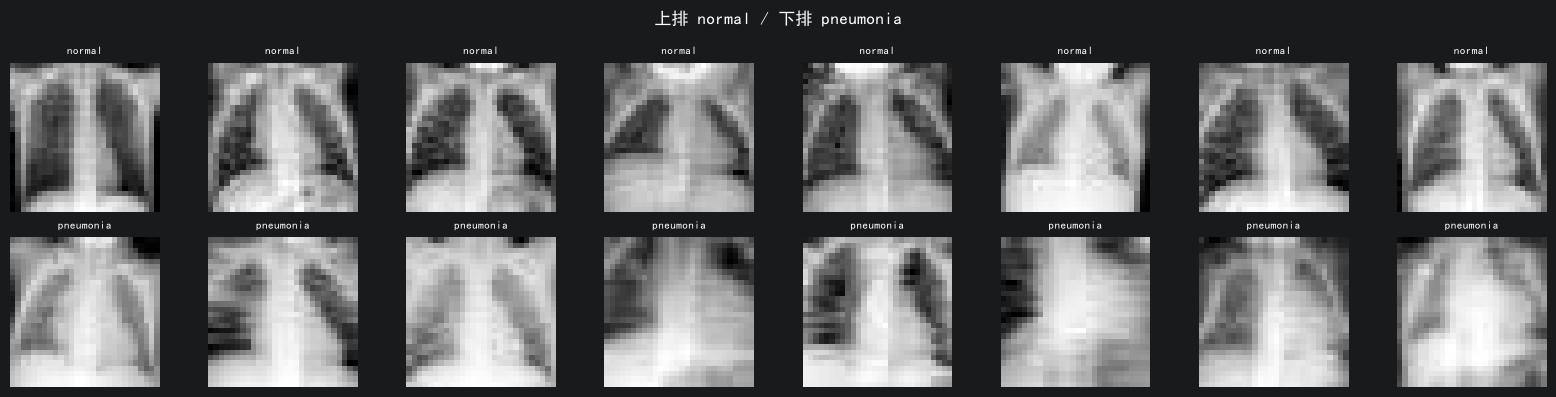

In [15]:
# 正常 vs 肺炎，各挑 8 张对照着看
lab_all = np.asarray(train_set.labels).ravel()
idx_normal = np.where(lab_all == 0)[0][:8]
idx_pneum = np.where(lab_all == 1)[0][:8]

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for ax, i in zip(axes[0], idx_normal):
    ax.imshow(train_set[int(i)][0].squeeze(), cmap='gray')
    ax.set_title('normal', fontsize=8)
    ax.axis('off')
for ax, i in zip(axes[1], idx_pneum):
    ax.imshow(train_set[int(i)][0].squeeze(), cmap='gray')
    ax.set_title('pneumonia', fontsize=8)
    ax.axis('off')
plt.suptitle('上排 normal / 下排 pneumonia')
plt.tight_layout()
plt.show()


In [17]:
import pydicom
from pydicom.data import get_testdata_file

# pydicom 自带一张真实 CT，任何装了 pydicom 的机器都能取到
# 换成自己的片子时，改这一行：pydicom.dcmread(r"E:\真实路径\xxx.dcm")
ds = pydicom.dcmread(get_testdata_file("CT_small.dcm"))

print("模态:", ds.Modality)                          # CT
print("尺寸:", ds.Rows, "x", ds.Columns)
print("像素间距:", ds.PixelSpacing)                  # ['0.661468', '0.661468']
print("层厚:", getattr(ds, 'SliceThickness', '无'))
print("像素数据形状:", ds.pixel_array.shape)
print("数据类型:", ds.pixel_array.dtype)

# 一些常被忽略但论文要报的
print("制造商:", getattr(ds, 'Manufacturer', '无'))
print("管电压:", getattr(ds, 'KVP', '无'))
print("窗位/窗宽:", getattr(ds, 'WindowCenter', '无'), getattr(ds, 'WindowWidth', '无'))

模态: CT
尺寸: 128 x 128
像素间距: [0.661468, 0.661468]
层厚: 5.000000
像素数据形状: (128, 128)
数据类型: int16
制造商: GE MEDICAL SYSTEMS
管电压: 120
窗位/窗宽: 无 无


In [21]:
import numpy as np
pixels = ds.pixel_array
print(f"换算前:{pixels.min()}~{pixels.max()}")

#HU换算
# 两个标签名都要拼对：拼错时 getattr 静默返回默认值，
# 算出来的数看着像 HU，其实等于没换算
slope = float(getattr(ds,'RescaleSlope',1))
intercept = float(getattr(ds,'RescaleIntercept',0))
hu = pixels.astype(np.float32) * slope + intercept

print(f"换算后: {hu.min():.1f} ~ {hu.max():.1f}")

# 验证：整张图最小值应接近 -1000（空气）
print("最小值:", hu.min(), "最大值:", hu.max())

# 按 HU 区间数像素，看清这张图里都有什么
bins = [(-9999,-900,'纯空气'), (-900,-500,'肺'), (-500,-100,'脂肪/肺'),
        (-100,100,'软组织/水'), (100,500,'骨松质'), (500,2000,'骨')]
for lo, hi, name in bins:
    n = int(((hu>=lo)&(hu<hi)).sum())
    print(f"  HU [{lo:6d},{hi:6d}) {name:8s}: {n:6d} 像素")


换算前:128~2191
换算后: -896.0 ~ 1167.0
最小值: -896.0 最大值: 1167.0
  HU [ -9999,  -900) 纯空气     :      0 像素
  HU [  -900,  -500) 肺       :   3514 像素
  HU [  -500,  -100) 脂肪/肺    :   1118 像素
  HU [  -100,   100) 软组织/水   :   8497 像素
  HU [   100,   500) 骨松质     :   2802 像素
  HU [   500,  2000) 骨       :    453 像素


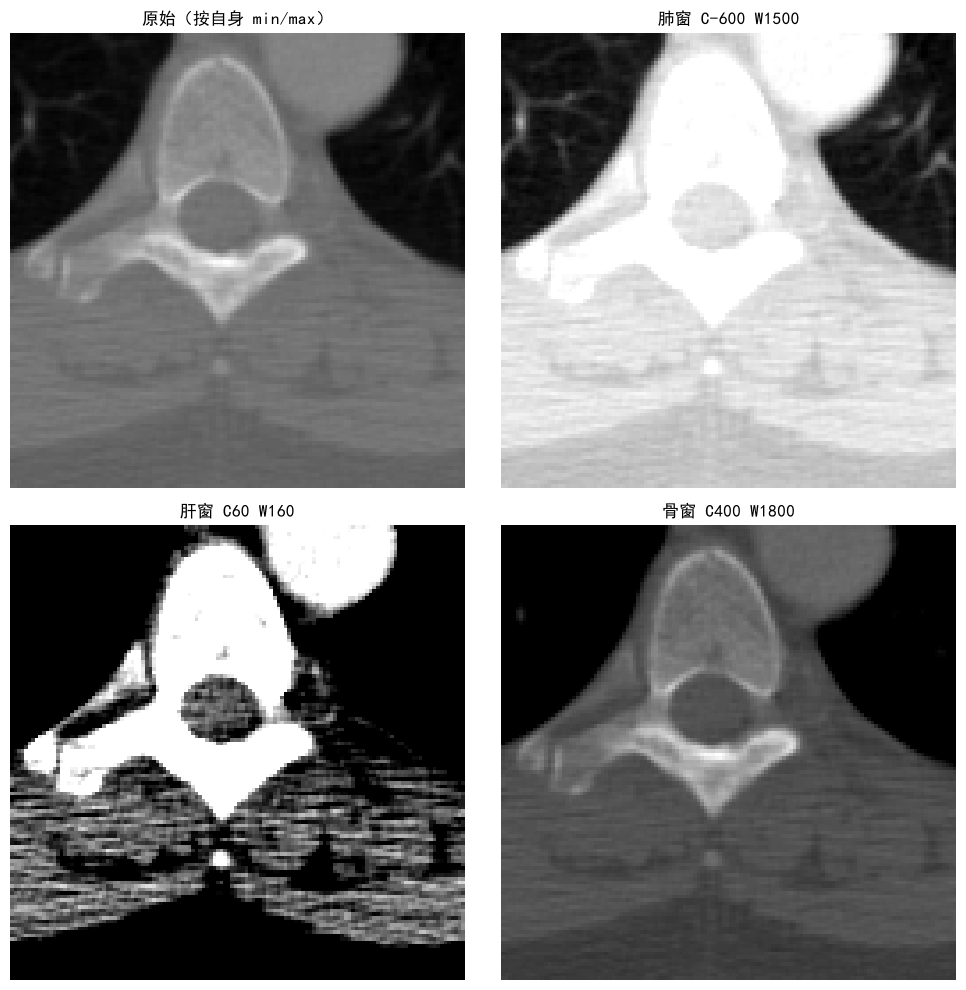

肺窗 C-600 W1500: 显示范围 [-1350, 150]  每级灰度 = 5.88 HU
肝窗 C60 W160: 显示范围 [-20, 140]  每级灰度 = 0.63 HU
骨窗 C400 W1800: 显示范围 [-500, 1300]  每级灰度 = 7.06 HU


In [1]:
# 练习 4-1-C：四种窗对比（2x2）
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from pydicom.data import get_testdata_file

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

ds = pydicom.dcmread(get_testdata_file("CT_small.dcm"))
hu = (ds.pixel_array.astype(np.float32)
      * float(getattr(ds, 'RescaleSlope', 1))
      + float(getattr(ds, 'RescaleIntercept', 0)))


def apply_window(img_hu, center, width):
    low = center - width / 2
    high = center + width / 2
    img = np.clip(img_hu, low, high)
    return ((img - low) / (high - low) * 255).astype(np.uint8)


panels = [
    ('原始（按自身 min/max）', None),
    ('肺窗 C-600 W1500', (-600, 1500)),
    ('肝窗 C60 W160',    (60,   160)),
    ('骨窗 C400 W1800',  (400, 1800)),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, (name, win) in zip(axes.flat, panels):
    if win is None:
        ax.imshow(hu, cmap='gray')
    else:
        ax.imshow(apply_window(hu, *win), cmap='gray')
    ax.set_title(name)
    ax.axis('off')
plt.tight_layout()
plt.show()

for name, win in panels[1:]:
    c, w = win
    print(f"{name}: 显示范围 [{c-w/2:.0f}, {c+w/2:.0f}]  每级灰度 = {w/255:.2f} HU")


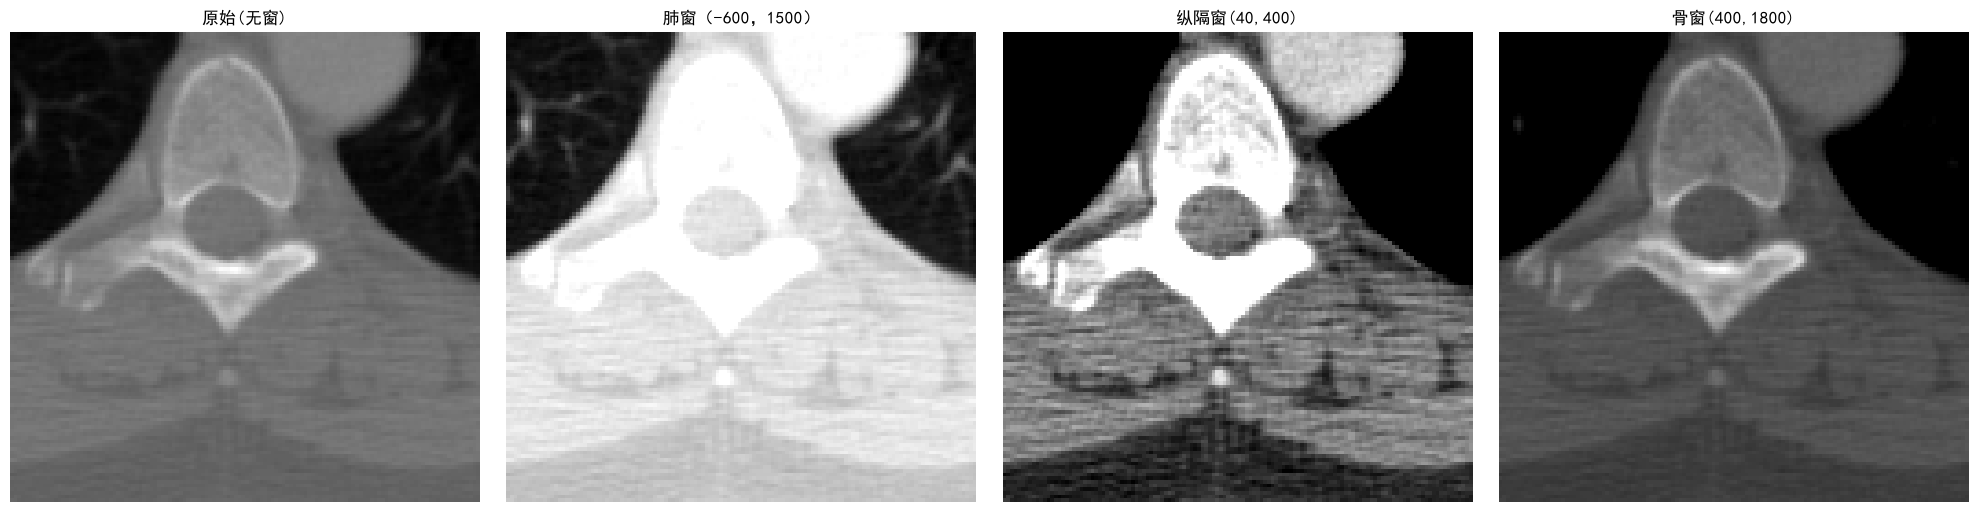

In [1]:
# ============================================================
# 一格四窗：同一张 CT，用四套窗各显示一次（1 行 4 列）
# 这格是自包含的，单独跑也能用
# ============================================================

import numpy as np                                   # np.clip、数组运算
import matplotlib.pyplot as plt                      # 画图
import pydicom                                       # 读 .dcm 文件
from pydicom.data import get_testdata_file           # 取 pydicom 自带的示例 CT

plt.rcParams['font.sans-serif'] = ['SimHei']         # 中文字体，标题不变方块
plt.rcParams['axes.unicode_minus'] = False           # 负号正常显示

# ---------- 1. 读文件 → 换算成 HU ----------
ds = pydicom.dcmread(get_testdata_file("CT_small.dcm"))   # ds = 整个数据集对象
hu = (ds.pixel_array.astype(np.float32)                   # 原始整数 int16，先转 float32
      * float(getattr(ds, 'RescaleSlope', 1))             # 斜率；标签缺失就用 1
      + float(getattr(ds, 'RescaleIntercept', 0)))        # 截距；这个文件是 -1024
# 换算是条直线：HU = 原始值 × 斜率 + 截距
# 实际效果 HU = 原始值 - 1024，范围 128~2191 变成 -896~1167
# 不换算直接用原始值开窗，整张图会全白

# ---------- 2. 开窗函数 ----------
def apply_window(img, center, width):
    # img    : 输入的 HU 图（128×128 数组）
    # center : 窗位 —— 看哪一段的中心（肺窗 -600）
    # width  : 窗宽 —— 这一段有多宽（肺窗 1500）
    low  = center - width / 2        # 窗下沿：-600 - 750 = -1350
    high = center + width / 2        # 窗上沿：-600 + 750 = +150
    img  = np.clip(img, low, high)   # 剪刀：低于 -1350 抬成 -1350，高于 150 压成 150
    return ((img - low) / (high - low) * 255).astype(np.uint8)
    #      （值 - 下沿）÷ 整段宽度  →  全部落到 0.0 ~ 1.0
    #      × 255                    →  换成屏幕亮度 0~255
    #      .astype(np.uint8)        →  砍掉小数，变成整数
    # 四个例子：-1400 → 0 黑   -900 → 76 深灰   0 → 229 近白   200 → 255 纯白

# ---------- 3. 菜单：四套窗 ----------
# 键 = 图上要写的标题，值 = 传给 apply_window 的两个数（打包成元组）
# None 表示这一格不开窗
windows = {
    '原始(无窗)': None,                  # 第 1 格：直接显示
    '肺窗（-600，1500）': (-600, 1500),   # 第 2 格：center=-600, width=1500
    '纵隔窗(40,400)': (40, 400),         # 第 3 格：center=40,   width=400
    '骨窗(400,1800)': (400, 1800),       # 第 4 格：center=400,  width=1800
}
# 字典的顺序 = 写进去的顺序（Python 3.7+），所以第 1 个格子一定是"原始"

# ---------- 4. 画图 ----------
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
# fig   = 整张画布；axes = 4 个格子（1 行 4 列，本身已经是一维，不用 .flat）
# figsize 是英寸：20 英寸宽 × 5 英寸高，扁长条，适合放一排横图

# 下面反复出现的 cmap='gray' 是「颜色映射表」：把 0~255 的数字翻译成颜色
#   'gray' → 0 黑、128 灰、255 白，CT 就该用这个
#   不写的话用默认彩色表，黑白片会被画成蓝红绿的花图

for ax, (name, w) in zip(axes, windows.items()):
    # zip: 把「4 个格子」和「4 对 (标题, 参数)」一对一扣起来，转 4 圈
    # windows.items() 每轮给一个 (键, 值)，括号再把它拆成 name 和 w
    if w is None:
        # 不开窗：直接把 hu 交给 matplotlib，它按自身最小/最大值自动缩放
        ax.imshow(hu, cmap='gray')
    else:
        # *w 把元组 (-600,1500) 拆成两个参数，等价于 apply_window(hu, -600, 1500)
        # 不拆会报 TypeError；顺序反了会算出 low > high，整张图变纯白
        ax.imshow(apply_window(hu, *w), cmap='gray')
    ax.set_title(name)                      # 贴标题（字典的键）
    ax.axis('off')                          # 关掉周围的坐标刻度尺

plt.tight_layout()                          # 自动调间距，防止标题和图挤在一起
plt.show()                                  # 前面只是"往格子里放"，这句才真正画出来


In [1]:
# ============================================================
# 一次性导入这一讲要用的库
# ============================================================
import numpy as np                    # 数组运算：np.clip、np.where、np.percentile
import matplotlib.pyplot as plt       # 画图
import torch                          # 张量 + 自动求导
import torch.nn as nn                 # 网络层：Conv2d / ReLU / MaxPool2d / Linear / Flatten
import torch.optim as optim           # 优化器：Adam、SGD
from torch.utils.data import DataLoader   # 分批喂数据的"发牌员"
from torchvision import transforms        # 图像预处理：ToTensor 在这里，不在 torch.utils.data
import medmnist                       # 医学图像数据集（MedMNIST）
from medmnist import INFO             # 数据集信息字典：类别名、通道数、样本数
from pathlib import Path              # 路径处理，比字符串拼路径更安全

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

ROOT = Path(r'E:\AI学习\练习代码\data\medmnist')   # 数据放 E 盘，不占 C 盘
ROOT.mkdir(parents=True, exist_ok=True)            # 目录要自己建

data_flag = 'pneumoniamnist'
info = INFO[data_flag]
#getattr——把字符串变成类
DataClass = getattr(medmnist,info['python_class'])

In [2]:
# 必要的库
import numpy as np                  # 数组计算：np.clip 截断、np.float32 转类型
import matplotlib.pyplot as plt     # 画图：plt.subplots / imshow
import torch                        # 张量 + 自动求导
import torch.nn as nn               # 网络层：Conv2d、ReLU、MaxPool2d、Linear、Flatten
import torch.optim as optim         # 优化器：Adam（负责改参数）
from torch.utils.data import DataLoader   # 把数据集切成一批一批喂给模型
from torchvision import transforms        # 图像预处理，ToTensor 在这里
import medmnist                     # 医学图像数据集库
from medmnist import INFO           # 数据集档案字典（类别名、通道数）
from pathlib import Path            # 路径对象，比字符串拼路径安全

plt.rcParams['font.sans-serif'] = ['SimHei']    # 中文字体，标题不变方块
plt.rcParams['axes.unicode_minus'] = False      # 负号正常显示

ROOT = Path(r'E:\AI学习\练习代码\data\medmnist')   # r = 原始字符串，反斜杠不当转义
ROOT.mkdir(parents=True, exist_ok=True)              # 目录不存在就建，已存在不报错

data_flag = 'pneumoniamnist'                         # 数据集编号，全小写
info = INFO[data_flag]                               # 查档案：类别、通道、样本数
DataClass = getattr(medmnist, info['python_class'])  # 把 'PneumoniaMNIST' 字符串取成真正的类

print("任务：", info['task'])           # binary-class
print("标签: ", info['label'])          # {'0': 'normal', '1': 'pneumonia'}
print("通道数: ", info['n_channels'])   # 1

# ToTensor 把 PIL 图片变成 (1,28,28) 的 float 张量，像素 0~255 压到 0~1
# 不写 transform，拿到的是 PIL.Image，网络吃不进去
transform = transforms.Compose([transforms.ToTensor()])

# 三个数据集各建一次：训练学，验证调，测试只碰一次
train_set = DataClass(split='train', transform=transform, download=True, root=str(ROOT))
val_set   = DataClass(split='val',   transform=transform, download=True, root=str(ROOT))
test_set  = DataClass(split='test',  transform=transform, download=True, root=str(ROOT))

print()
print("样本数：训练", len(train_set), "验证", len(val_set), "测试", len(test_set))

# 取一张看看长什么样
x, y = train_set[0]
# x.shape = [1, 28, 28]：1 是通道数（灰度），28x28 是高和宽
# y 是 numpy 数组 [1]，值 0/1；str() 之后才能当字典键去查 info['label']
print("单张:", x.shape, "标签:", info['label'][str(y[0])])

任务： binary-class
标签:  {'0': 'normal', '1': 'pneumonia'}
通道数:  1

样本数：训练 4708 验证 524 测试 624
单张: torch.Size([1, 28, 28]) 标签: pneumonia


使用设备: cuda
训练4708/验证524/测试624
标签: {'0': 'normal', '1': 'pneumonia'}
参数量: 219714
Epoch  1  train loss=0.3010 acc=0.8662 | val loss=0.1711 acc=0.9408
Epoch  2  train loss=0.1513 acc=0.9437 | val loss=0.1293 acc=0.9427
Epoch  3  train loss=0.1333 acc=0.9480 | val loss=0.1252 acc=0.9580
Epoch  4  train loss=0.1219 acc=0.9528 | val loss=0.1169 acc=0.9542
Epoch  5  train loss=0.1110 acc=0.9573 | val loss=0.1089 acc=0.9618
Epoch  6  train loss=0.0993 acc=0.9654 | val loss=0.0924 acc=0.9637
Epoch  7  train loss=0.0913 acc=0.9671 | val loss=0.0972 acc=0.9599
Epoch  8  train loss=0.0866 acc=0.9701 | val loss=0.0850 acc=0.9676
Epoch  9  train loss=0.0854 acc=0.9679 | val loss=0.0866 acc=0.9676
Epoch 10  train loss=0.0735 acc=0.9741 | val loss=0.0883 acc=0.9637

===== 测试集（10 轮，阈值 0.5）=====
混淆矩阵:
[[159  75]
 [  5 385]]
  TN=159  FP=75
  FN=5  TP=385
准确率 Accuracy     : 0.8718
召回率 Recall       : 0.9872
精确率 Precision    : 0.8370
特异度 Specificity  : 0.6795
F1                  : 0.9059
AUC               

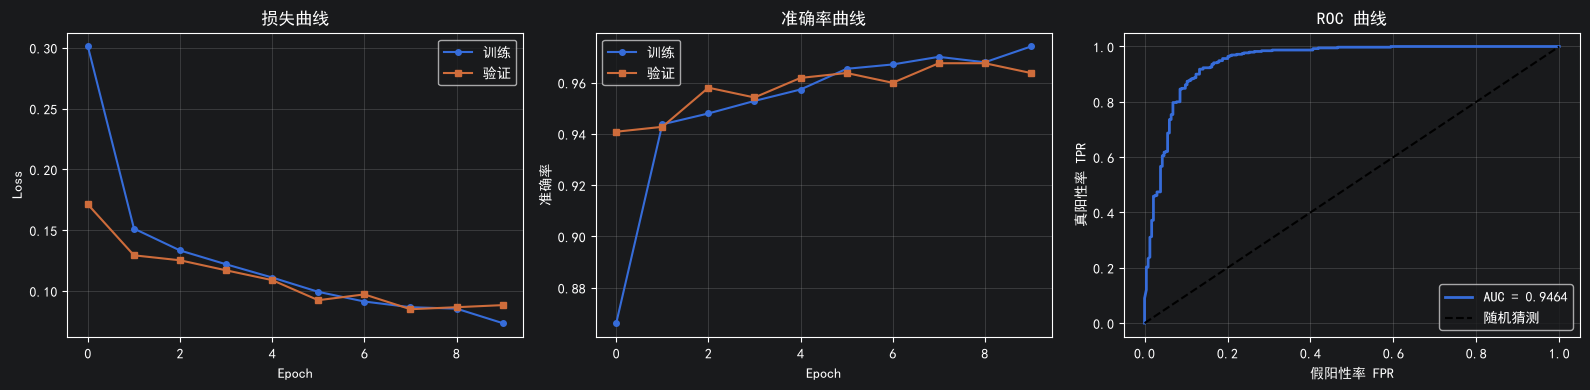

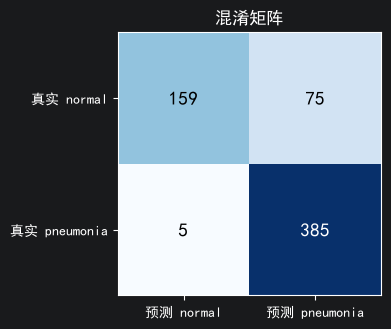

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader   # 把数据集按批交给模型
from torchvision import transforms        # 预处理：ToTensor / Normalize
import medmnist                           # 医学影像数据集库
from medmnist import INFO                 # 数据集档案：类别、通道数
from pathlib import Path                  # 路径对象

# 评估指标：全部输入 (真实标签, 预测结果)
from sklearn.metrics import (
    accuracy_score,      # 准确率  (TP+TN)/N          错的和对的混在一起算
    precision_score,     # 精确率  TP/(TP+FP)          判成肺炎的人里几个真病
    recall_score,        # 召回率  TP/(TP+FN)          真病人里抓到几个，漏诊的反面
    f1_score,            # F1      2PR/(P+R)           精确率和召回率的调和平均
    confusion_matrix,    # 混淆矩阵 [[TN,FP],[FN,TP]]  四个格子分得清哪种错
    roc_auc_score,       # AUC     ROC 曲线下面积        输入要「概率」，不能给 0/1
    roc_curve,           # ROC 曲线点  返回 fpr, tpr, thresholds 三个数组
)

plt.rcParams['font.sans-serif'] = ['SimHei']    # 中文标题不变方块
plt.rcParams['axes.unicode_minus'] = False      # 负号正常显示

torch.manual_seed(42)                           # 固定 CPU 随机种子
# 下面三行固定 GPU 的随机性，保证重复运行结果完全一致（代价是训练稍慢）
torch.backends.cudnn.deterministic = True       # 卷积算法选确定的那个，不选最快的
torch.backends.cudnn.benchmark = False          # 关掉自动算法搜索
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":                             # 注意是 cuda，不是 cude
    torch.cuda.manual_seed_all(42)               # 固定所有 GPU 的随机种子
print("使用设备:", device)

# 数据
ROOT = Path(r'E:\AI学习\练习代码\data\medmnist')
ROOT.mkdir(parents=True, exist_ok=True)          # 目录不存在就建，已存在不报错

# INFO 是 medmnist 自带的一张总表：{数据集名: 该数据集的全部档案}
# 共 18 个数据集（12 个 2D + 6 个 3D），格式一致：INFO['pneumoniamnist']、INFO['bloodmnist'] ...
# 每个档案是一本字典，常用键：
#   python_class = 'PneumoniaMNIST'   类名（字符串，要用 getattr 变类）
#   task         = 'binary-class'     任务类型：二分类 / 多分类 / 多标签
#   label        = {'0':'normal','1':'pneumonia'}   标签表：编号 → 中文/英文名
#   n_channels   = 1                  通道数：灰度 1，彩色 3
#   n_samples    = {'train':4708,'val':524,'test':624}   三个划分各多少张
#   url / MD5    = 下载地址 / 文件校验码
# 想看全部 18 个数据集：print(INFO.keys())
data_flag = 'pneumoniamnist'                     # 数据集编号，全小写
info = INFO[data_flag]                           # 查总表，得到一整套档案（字典）
# getattr(对象, "名字字符串") = 在对象里找叫这个名字的东西
# 'PneumoniaMNIST' 只是字符串，不能用；getattr 把它取成真正的类
# 等价于 medmnist.PneumoniaMNIST，但换数据集时只改上面一行就够了
DataClass = getattr(medmnist, info['python_class'])
n_classes = len(info['label'])                   # 数标签表有几个键 → 2
label_names = info['label']                      # {'0':'normal', '1':'pneumonia'}

# 名字 → 查总表得档案 → getattr 把类名取成真正的类 → len 数出类别数
# 全程没有手写任何数字，换数据集只改 data_flag 一行

# ToTensor：PIL → Tensor，(28,28) → (1,28,28)，0~255 → 0~1
# Normalize(0.5,0.5)：(x-0.5)/0.5，把 0~1 压到 -1~1，数据中心化后梯度下降更稳
train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5],std=[0.5]),
])
# 验证/测试必须用和训练完全一样的变换，否则输入分布不一致，指标不可信
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5],std=[0.5]),
])
train_set = DataClass(split='train',transform=train_transform,download=True,root=str(ROOT))
val_set = DataClass(split='val',transform=eval_transform,download=True,root=str(ROOT))
test_set = DataClass(split='test',transform=eval_transform,download=True,root=str(ROOT))

print(f"训练{len(train_set)}/验证{len(val_set)}/测试{len(test_set)}")
print("标签:", label_names)

# 训练集打乱（每轮顺序不同，防止记住顺序）；验证/测试不打乱
train_loader = DataLoader(train_set,batch_size=64,shuffle=True)
val_loader = DataLoader(val_set,batch_size=64,shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=64, shuffle=False)

#模型
class MedCNN(nn.Module):
    def __init__(self, in_ch, n_cls):
        super().__init__()
        #特征提取,通道1➡32➡64，尺寸28➡14➡7
        self.features = nn.Sequential(
            nn.Conv2d(in_ch,32,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        #分类：64通道 *7 *7 = 3136
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 64),
            nn.ReLU(),
            nn.Dropout(0.3),          # 随机丢弃 30% 神经元
            nn.Linear(64, n_cls),
        )

    def forward(self,x):
        return self.classifier(self.features(x))

# 这行做两件事，顺序不能换：
# ① MedCNN(info['n_channels'], n_classes)
#      造模型：按参数搭出网络结构，并随机初始化权重
#      n_channels=1 → Conv2d 入口收 1 通道（灰度图）
#      n_classes =2 → 最后一层 Linear 输出 2 个分数
#      这一步模型还在 CPU 上（不管 device 写的是什么）
# ② .to(device)
#      把模型的所有参数（权重+偏置）搬到 device 指定的设备
#      device='cuda' → 拷到显卡显存；'cpu' → 留在内存
#      返回新对象，所以要赋值回来：model = ...
#
# 为什么必须搬：模型和数据必须在同一台设备上，否则
#   RuntimeError: Expected all tensors to be on the same device
# 训练时每一批数据也要 .to(device)，两边对齐才能算
#学生，负责打分
model = MedCNN(info['n_channels'], n_classes).to(device)
# ---------- 参数量怎么算 ----------
# 参数量 = 所有权重 + 所有偏置的「数字个数」，不算维度
#   Conv2d 权重: out_c × in_c × k × k   偏置: out_c
#   Linear 权重: out × in                偏置: out
# 本模型逐层：
#   Conv1  (1→32, 3×3) : 32×1×3×3 + 32 =   288 + 32  =    320
#   Conv2 (32→64, 3×3) : 64×32×3×3 + 64 = 18432 + 64 =  18496
#   FC1  (3136→64)     : 64×3136 + 64   = 200704 + 64 = 200768   ← 91.4% 都堆在这
#   FC2  (64→2)        : 2×64 + 2       =   128 + 2  =    130
#   合计 = 320 + 18496 + 200768 + 130 = 219714
# ReLU / MaxPool / Flatten / Dropout 没有参数，不计入

# model.parameters() 遍历所有「需要训练的张量」
# p.numel() = number of elements，这个张量里有多少个数字
# 逐个加起来就是总参数量
print("参数量:", sum(p.numel() for p in model.parameters()))

#打分规则
criterion = nn.CrossEntropyLoss() #多分类交叉熵，内部自带softmax
#根据错题调整学生的学习习惯
optimizer = optim.Adam(model.parameters(),lr=1e-3)

#epoch，定义run_epoch作为模型存在的函数
def run_epoch(model,loader,train=True):
    #train模式打开Dropout；eval模式关闭Dropout并切换BatchNorm
    model.train() if train else model.eval()
    total_loss,correct,total = 0.0, 0, 0

    #训练要算梯度，评估不需要算梯度
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for xb,yb in loader:
            xb = xb.to(device)
            #squeeze挤掉了长度1的维度，所以输出（64，1）变成了（64， ）
            #.long()转化成int64,分类标签必须是整数
            yb = yb.squeeze().long().to(device)

            if train:
                optimizer.zero_grad()#梯度会累加，必须清零

            out = model(xb)#前向传播
            loss = criterion(out,yb)#计算损失

            if train:
                loss.backward()#反向传播
                optimizer.step()#梯度更新

            #每个batch的loss是平均值，乘回batch大小才是总损失
            #（最后一个batch只有36张，直接平均会引入偏差）
            total_loss += loss.item()*xb.size(0)#记损失
            correct += (out.argmax(1) == yb).sum().item()#记答对几个
            total += xb.size(0)#记这批有几张
    #每轮可以输出平均损失和准确率，方便判断模型是否提升
    return total_loss / total,correct / total

#训练10轮
#创建了一个空字典，用来保存每一轮训练的四个指标，四个框对应四条记录：
#训练损失、验证损失、训练准确率、验证准确率
history = {'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[]}

for epoch in range(10):
    tr_loss,tr_acc = run_epoch(model,train_loader,train=True)
    va_loss,va_acc = run_epoch(model,val_loader,train=False)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(va_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(va_acc)

    print(f"Epoch {epoch+1:2d}  "
          f"train loss={tr_loss:.4f} acc={tr_acc:.4f} | "
          f"val loss={va_loss:.4f} acc={va_acc:.4f}")

#测试集
#模型进入考试模式，关闭随机丢弃
model.eval()
y_true,y_pred,y_prob = [], [], []

with torch.no_grad():
    for xb,yb in test_loader:
        xb = xb.to(device)
        logits = model(xb)
        #把分数变成概率
        prob = torch.softmax(logits,dim=1)[:,1]
        #抄下肺炎把握分数
        y_prob.extend(prob.cpu().numpy())
        #选择分数较高的那个
        y_pred.extend(logits.argmax(1).cpu().numpy())
        #抄下标准答案
        y_true.extend(yb.squeeze().long().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

acc = accuracy_score(y_true, y_pred) #(TP+TN)/总数
rec = recall_score(y_true, y_pred) #TP/(TP+FN)病人里面抓到几个
prec = precision_score(y_true, y_pred) #TP/(TP+FP)判成肺炎的里面有几个真病
spec = tn / (tn + fp) #TN/(TN + FP)健康人里判对几个
f1 = f1_score(y_true, y_pred) #2PR/(P+R)
aucc = roc_auc_score(y_true,y_prob) #ROC曲线下面积

print("\n===== 测试集（10 轮，阈值 0.5）=====")
print(f"混淆矩阵:\n{cm}")
print(f"  TN={tn}  FP={fp}")
print(f"  FN={fn}  TP={tp}")
print(f"准确率 Accuracy     : {acc:.4f}")
print(f"召回率 Recall       : {rec:.4f}")
print(f"精确率 Precision    : {prec:.4f}")
print(f"特异度 Specificity  : {spec:.4f}")
print(f"F1                  : {f1:.4f}")
print(f"AUC                 : {aucc:.4f}")

# 手算校验：每个数都能自己对上，才算真懂
print("\n===== 手算校验 =====")
print(f"准确率 = (TN+TP)/总数 = ({tn}+{tp})/{len(y_true)} = {(tn+tp)/len(y_true):.4f}")
print(f"召回率 = TP/(TP+FN)   = {tp}/({tp}+{fn}) = {tp/(tp+fn):.4f}")
print(f"精确率 = TP/(TP+FP)   = {tp}/({tp}+{fp}) = {tp/(tp+fp):.4f}")
print(f"特异度 = TN/(TN+FP)   = {tn}/({tn}+{fp}) = {tn/(tn+fp):.4f}")
#图
#plt.subplots：一次性创建一张画布，并在画布上排好多个子图
#figsize=(16, 4)：整张画布宽 16 英寸、高 4 英寸
#fig：整张画布对象
#axes：一个装着 3 个子图的数组，形状是 (3,)
fig,axes = plt.subplots(1,3,figsize=(16,4))
#marker='o'，画圆圈
#ms=4，圆圈大小是 4 个点（ms 是 markersize 的缩写）
axes[0].plot(history['train_loss'],label='训练',marker='o',ms=4)
axes[0].plot(history['val_loss'],   label='验证', marker='s', ms=4)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('损失曲线'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history['train_acc'], label='训练', marker='o', ms=4)
axes[1].plot(history['val_acc'],   label='验证', marker='s', ms=4)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('准确率')
axes[1].set_title('准确率曲线'); axes[1].legend(); axes[1].grid(alpha=0.3)

fpr, tpr, _ = roc_curve(y_true, y_prob)
axes[2].plot(fpr, tpr, linewidth=2, label=f'AUC = {aucc:.4f}')
axes[2].plot([0, 1], [0, 1], 'k--', label='随机猜测')
axes[2].set_xlabel('假阳性率 FPR'); axes[2].set_ylabel('真阳性率 TPR')
axes[2].set_title('ROC 曲线'); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 混淆矩阵热图
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)
ax.set_xticks([0, 1]); ax.set_xticklabels(['预测 normal', '预测 pneumonia'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['真实 normal', '真实 pneumonia'])
ax.set_title('混淆矩阵')
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 测试集评估（只跑一次）
# ============================================================
# 测试集是「最终考试」。
# 在验证集上调了 10 轮之后再拿测试集调参，这次考试就不作数了。
# 所以：跑一次，记录数字，不要根据它回去改模型。

print("开始评估测试集（624 张）...")
test_loss, test_acc = run_epoch(model, test_loader, train=False)

print()
print("=" * 56)
print(f"测试集   loss={test_loss:.4f}   acc={test_acc:.4f}")
print(f"验证集   loss=0.0850   acc=0.9676   （第 8 轮，最好的一次）")
print("=" * 56)

gap = abs(0.9676 - test_acc)
print()
print(f"两者差距: {gap:.4f}")
if gap < 0.01:
    print("→ 正常。测试集和验证集表现一致，说明模型没有过度依赖验证集。")
elif gap < 0.03:
    print("→ 有差距但可接受。可能测试集和验证集的病人分布略有不同。")
else:
    print("→ 差距偏大。要查测试集和训练集是不是来自同一批数据。")


In [ ]:
# ============================================================
# 保存模型
# ============================================================
# 训完不存，下次要重新跑 10 轮。
# 存什么：权重 + 关键指标，方便以后查「这个文件是哪次训的」

from pathlib import Path
import torch

save_dir = Path("models")
save_dir.mkdir(exist_ok=True)
save_path = save_dir / "medcnn_pneumonia.pt"

torch.save({
    "model_state": model.state_dict(),
    "test_acc": test_acc,                    # 上一个单元算的
    "val_acc_best": 0.9676,
    "param_count": sum(p.numel() for p in model.parameters()),
    "arch": "MedCNN",
}, save_path)

print(f"已保存: {save_path.resolve()}")
print(f"大小:   {save_path.stat().st_size / 1024:.0f} KB")
print()
print("以后要用这个模型，不用重新训练：")
print('    ckpt = torch.load("models/medcnn_pneumonia.pt")')
print("    model.load_state_dict(ckpt['model_state'])")
print("    model.eval()")
